# Phân loại bệnh lá cà tím (Eggplant Leaf Disease) — EfficientNet-B0, **đủ 6 lớp**

Notebook này viết lại toàn bộ pipeline từ các notebook trước của bạn (RAM-cache ảnh dạng `uint8`, split cố định, `RandomizedSearchCV` + `PredefinedSplit`, Focal / Weighted loss, CBAM...) nhưng **dự đoán đủ 6 nhãn**:

`Healthy Leaf · Insect Pest Disease · Leaf Spot Disease · Mosaic Virus Disease · White Mold Disease · Wilt Disease`

Hai lớp mới (`White Mold` ≈ 63 ảnh, `Wilt` ≈ 65 ảnh) rất hiếm so với `Healthy Leaf` (≈ 1451 ảnh), tỉ lệ mất cân bằng khoảng **23 : 1**, nên phần xử lý imbalance quan trọng hơn nhiều so với bản 4 lớp.

## Bốn thí nghiệm chạy tuần tự

| Thí nghiệm | Nội dung | Mục đích |
|---|---|---|
| **A** | EfficientNet-B0 **pretrained ImageNet**, fine-tune toàn mạng, CE thường | Baseline transfer learning |
| **B** | EfficientNet-B0 **train from scratch** (cùng kiến trúc, cùng pipeline) | Đo giá trị của pretrained |
| **C** | **RandomizedSearchCV**: loss (CE / weighted CE / Focal / weighted Focal / Class-Balanced), optimizer (AdamW / Adam / SGD / RMSprop ± SAM), sampler, label smoothing, scheduler, learning rate, freeze... | Tối ưu siêu tham số + xử lý imbalance |
| **D** | **Cải tiến EfficientNet-B0 để đạt accuracy cao nhất**: chọn tiến dần (greedy) từng thành phần theo validation, sau đó **ensemble 5-fold + TTA** | Kết quả tốt nhất |

## Quy ước để so sánh công bằng

* Một split **stratified cố định** `70 / 15 / 15` (train / val / test), dùng chung cho mọi thí nghiệm. Test set chỉ dùng để **báo cáo**, không dùng để chọn mô hình hay siêu tham số.
* Validation dùng cho checkpoint, early stopping và chọn cấu hình. Tiêu chí chính là **accuracy** (macro-F1 làm tie-break và luôn được báo cáo kèm).
* A, B, C dùng ảnh 224×224 và augmentation "basic" (đúng bộ augmentation trong notebook cũ của bạn: flip, xoay ±15°, blur, nhiễu Gaussian, brightness, nhưng áp dụng **online trên GPU** thay vì sinh file). D mới được nâng cấp thêm.
* Không có DataLoader/multiprocessing: ảnh decode **một lần**, lưu RAM (và lưu `.npy` ra đĩa), augmentation chạy trên GPU. Cách này tránh lỗi treo DataLoader trên Windows mà bạn gặp trước đây.
* Có cơ chế **resume**: mọi model/trial đã chạy xong được lưu lại; nếu kernel bị ngắt, chạy lại cell sẽ bỏ qua phần đã xong.

> **Cách dùng:** đặt `SMOKE_TEST = True` ở cell cấu hình để chạy thử vài phút (kiểm tra pipeline và đo giây/epoch trên GPU của bạn), sau đó đặt về `False` rồi chạy toàn bộ.

## 0. Imports và cấu hình toàn cục

Toàn bộ ngân sách thời gian (số epoch, số trial...) nằm trong dict `BUDGET`. Bạn có thể tăng thêm nếu muốn chạy lâu hơn.

In [1]:
# ============================================================
# 0. Imports & cấu hình toàn cục
# ============================================================
import os, sys, gc, json, math, time, copy, random, hashlib, platform, warnings, traceback
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageFile
from IPython.display import display

import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import models
from torchvision.models import EfficientNet_B0_Weights

from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.model_selection import (
    train_test_split, StratifiedKFold, RandomizedSearchCV, PredefinedSplit
)
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_recall_fscore_support,
    classification_report, confusion_matrix, f1_score
)
from scipy.stats import loguniform, uniform

warnings.filterwarnings("ignore", category=UserWarning)
ImageFile.LOAD_TRUNCATED_IMAGES = True

# ----------------------------- cấu hình chính -----------------------------
SMOKE_TEST = False      # True = chạy thử rất nhanh để kiểm tra pipeline / đo tốc độ
SEED       = 42
RESUME     = True       # True = bỏ qua model/trial đã có checkpoint trong thư mục models/results

# Nếu notebook không tự tìm thấy dataset, hãy gán đường dẫn thủ công, ví dụ:
# DATASET_DIR = Path(r"D:\Code\AI\Eggplant_Leaf_Diseases\Dataset\Original_dataset")
DATASET_DIR = None

CLASSES = [
    "Healthy Leaf",
    "Insect Pest Disease",
    "Leaf Spot Disease",
    "Mosaic Virus Disease",
    "White Mold Disease",
    "Wilt Disease",
]
NUM_CLASSES = len(CLASSES)
CLASS_TO_IDX = {c: i for i, c in enumerate(CLASSES)}

TEST_FRAC, VAL_FRAC = 0.15, 0.15          # 70 / 15 / 15
BASE_SIZE, HIGH_SIZE = 224, 320           # 224 cho A/B/C, D có thể nâng lên 320
IMAGE_SIZES = (BASE_SIZE, HIGH_SIZE)

if SMOKE_TEST:
    BUDGET = dict(A_epochs=2, B_epochs=2, C_n_iter=3, C_search_epochs=2, C_final_epochs=3,
                  C_topk=2, D_epochs=3, D_longer_epochs=4, D_folds=2, per_class_cap=24)
else:
    BUDGET = dict(A_epochs=40, B_epochs=100, C_n_iter=40, C_search_epochs=25, C_final_epochs=60,
                  C_topk=3, D_epochs=60, D_longer_epochs=90, D_folds=5, per_class_cap=None)

OUT_TAG     = "smoke" if SMOKE_TEST else "full"
RESULTS_DIR = Path(f"results_6class_{OUT_TAG}")
MODELS_DIR  = Path(f"models_6class_{OUT_TAG}")
CACHE_DIR   = Path("cache_6class")                      # cache ảnh dùng chung
SEARCH_CACHE_DIR = RESULTS_DIR / "search_trials"
for d in (RESULTS_DIR, MODELS_DIR, CACHE_DIR, SEARCH_CACHE_DIR):
    d.mkdir(parents=True, exist_ok=True)

# ----------------------------- thiết bị / AMP -----------------------------
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"
AMP_DTYPE = torch.bfloat16 if (USE_AMP and torch.cuda.is_bf16_supported()) else torch.float16
torch.backends.cudnn.benchmark = True


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


set_seed(SEED)

print("Python    :", sys.version.split()[0], "|", platform.platform())
print("PyTorch   :", torch.__version__)
print("Device    :", DEVICE, "| AMP:", USE_AMP, "| AMP dtype:", AMP_DTYPE)
if DEVICE.type == "cuda":
    print("GPU       :", torch.cuda.get_device_name(0),
          "| VRAM %.1f GB" % (torch.cuda.get_device_properties(0).total_memory / 1e9))
else:
    print("CẢNH BÁO: không có CUDA, huấn luyện trên CPU sẽ cực kỳ chậm.")
print("SMOKE_TEST:", SMOKE_TEST)
print("BUDGET    :", BUDGET)

Python    : 3.11.9 | Windows-10-10.0.26200-SP0
PyTorch   : 2.11.0+cu130
Device    : cuda | AMP: True | AMP dtype: torch.bfloat16
GPU       : NVIDIA GeForce RTX 5060 Laptop GPU | VRAM 8.5 GB
SMOKE_TEST: False
BUDGET    : {'A_epochs': 40, 'B_epochs': 100, 'C_n_iter': 40, 'C_search_epochs': 25, 'C_final_epochs': 60, 'C_topk': 3, 'D_epochs': 60, 'D_longer_epochs': 90, 'D_folds': 5, 'per_class_cap': None}


## 1. Tìm thư mục `Original_dataset` và thu thập ảnh của đủ 6 lớp

Chỉ dùng ảnh nằm trong `Original_dataset` (không dùng thư mục augmented của Kaggle, để tránh rò rỉ dữ liệu giữa train và test).

In [2]:
# ============================================================
# 1. Tìm Original_dataset và thu thập ảnh của 6 lớp
# ============================================================
IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}


def find_original_dataset():
    cands = []
    if DATASET_DIR is not None:
        cands.append(Path(DATASET_DIR))
    cands += [
        Path("Eggplant_Leaf_Diseases") / "Dataset" / "Original_dataset",
        Path("Dataset") / "Original_dataset",
        Path("Original_dataset"),
    ]
    for c in cands:
        if c.is_dir():
            return c.resolve()
    for base in [Path.cwd(), Path.cwd().parent]:
        for root, dirs, _ in os.walk(base):
            depth = len(Path(root).relative_to(base).parts)
            if depth > 4:
                dirs[:] = []
                continue
            dirs[:] = [d for d in dirs if not d.startswith(".") and not d.startswith("cache_")
                       and not d.startswith("models_") and not d.startswith("results_")]
            if Path(root).name.lower() == "original_dataset":
                return Path(root).resolve()
    return None


SOURCE_DIR = find_original_dataset()
if SOURCE_DIR is None:
    raise FileNotFoundError(
        "Không tìm thấy thư mục 'Original_dataset'. Hãy gán DATASET_DIR ở cell cấu hình."
    )
print("Original_dataset:", SOURCE_DIR)


def _norm(s):
    return str(s).strip().casefold().replace("_", " ").replace("-", " ")


folders = {_norm(p.name): p for p in SOURCE_DIR.iterdir() if p.is_dir()}
missing = [c for c in CLASSES if _norm(c) not in folders]
if missing:
    raise FileNotFoundError(f"Thiếu thư mục lớp: {missing}. Hiện có: {[p.name for p in SOURCE_DIR.iterdir()]}")

records = []
for cls in CLASSES:
    for p in sorted(folders[_norm(cls)].rglob("*")):
        if p.is_file() and p.suffix.lower() in IMAGE_EXTS:
            records.append({"path": str(p.resolve()), "class_name": cls, "label": CLASS_TO_IDX[cls]})

df_all = pd.DataFrame(records).reset_index(drop=True)
df_all["idx"] = np.arange(len(df_all))        # chỉ số hàng trong cache ảnh
print("Tổng số ảnh tìm thấy:", len(df_all))
display(df_all["class_name"].value_counts().reindex(CLASSES).rename("count").to_frame())

Original_dataset: D:\Code\AI\Eggplant_Leaf_Diseases\Dataset\Original_dataset
Tổng số ảnh tìm thấy: 4089


,count
class_name,
Healthy Leaf,1451
Insect Pest Disease,546
Leaf Spot Disease,602
Mosaic Virus Disease,1362
White Mold Disease,63
Wilt Disease,65


## 2. Decode ảnh một lần → cache `uint8` (RAM + đĩa)

* Mỗi ảnh được decode **một lần**, resize (bilinear, có antialias) về cả `224×224` và `320×320`, rồi lưu thành `.npy` trong `cache_6class/`. Lần chạy sau nạp lại gần như tức thì.
* Ảnh hỏng/không đọc được bị loại và được báo cáo.
* Việc chuẩn hoá ImageNet và augmentation diễn ra trên GPU theo từng batch.

In [3]:
# ============================================================
# 2. Decode + resize một lần, lưu cache .npy
# ============================================================
def _decode_one(path, sizes):
    try:
        with Image.open(path) as im:
            try:
                im.draft("RGB", (max(sizes), max(sizes)))   # tăng tốc decode JPEG
            except Exception:
                pass
            im = im.convert("RGB")
            return {s: np.asarray(im.resize((s, s), Image.Resampling.BILINEAR), dtype=np.uint8)
                    for s in sizes}
    except Exception:
        return None


def build_or_load_cache(paths, sizes, workers=None):
    key = hashlib.md5("\n".join(paths).encode("utf-8")).hexdigest()[:12]
    files = {s: CACHE_DIR / f"img_{key}_{s}.npy" for s in sizes}
    vfile = CACHE_DIR / f"valid_{key}.npy"
    if all(f.exists() for f in files.values()) and vfile.exists():
        print("Nạp cache ảnh từ đĩa:", CACHE_DIR)
        return {s: np.load(f) for s, f in files.items()}, np.load(vfile)

    n = len(paths)
    arrays = {s: np.zeros((n, s, s, 3), np.uint8) for s in sizes}
    valid = np.zeros(n, dtype=bool)
    workers = workers or min(8, os.cpu_count() or 4)
    t0 = time.time()
    print(f"Decode {n} ảnh với {workers} luồng (chỉ chạy một lần)...")
    with ThreadPoolExecutor(max_workers=workers) as ex:
        for i, res in enumerate(ex.map(lambda p: _decode_one(p, sizes), paths)):
            if res is not None:
                valid[i] = True
                for s in sizes:
                    arrays[s][i] = res[s]
            if (i + 1) % 500 == 0 or i + 1 == n:
                print(f"  {i + 1}/{n}  ({time.time() - t0:.0f}s)")
    for s in sizes:
        np.save(files[s], arrays[s])
    np.save(vfile, valid)
    return arrays, valid


XS, VALID = build_or_load_cache(df_all["path"].tolist(), IMAGE_SIZES)
df_all["valid"] = VALID
bad = df_all[~df_all["valid"]]
print(f"Ảnh hợp lệ: {int(VALID.sum())} | ảnh hỏng bị loại: {len(bad)}")
if len(bad):
    bad.to_csv(RESULTS_DIR / "bad_images.csv", index=False)
    display(bad.head())
for s, a in XS.items():
    print(f"Cache {s}x{s}: {a.shape}, {a.nbytes / 1e9:.2f} GB")

df = df_all[df_all["valid"]].copy()
if BUDGET["per_class_cap"]:
    df = df.groupby("label", group_keys=False).head(BUDGET["per_class_cap"])
    print("SMOKE_TEST: giới hạn", BUDGET["per_class_cap"], "ảnh/lớp ->", len(df), "ảnh")
df = df.reset_index(drop=True)

Nạp cache ảnh từ đĩa: cache_6class
Ảnh hợp lệ: 4089 | ảnh hỏng bị loại: 0
Cache 224x224: (4089, 224, 224, 3), 0.62 GB
Cache 320x320: (4089, 320, 320, 3), 1.26 GB


## 3. EDA ngắn và split cố định 70 / 15 / 15

Split được stratified theo lớp, lưu ra CSV và tái sử dụng ở lần chạy sau (tạo tên file riêng `split6_*` để không lẫn với split 4 lớp cũ).

Với hai lớp hiếm, test chỉ có khoảng 9–10 ảnh/lớp. Mỗi ảnh sai thay đổi recall lớp đó khoảng 10 điểm phần trăm, nên hãy đọc kết quả theo từng lớp cùng với accuracy tổng.

,count,percent
class_name,,
Healthy Leaf,1451,35.49
Insect Pest Disease,546,13.35
Leaf Spot Disease,602,14.72
Mosaic Virus Disease,1362,33.31
White Mold Disease,63,1.54
Wilt Disease,65,1.59


Tỉ lệ mất cân bằng (lớp đông nhất / lớp hiếm nhất): 23.0 : 1


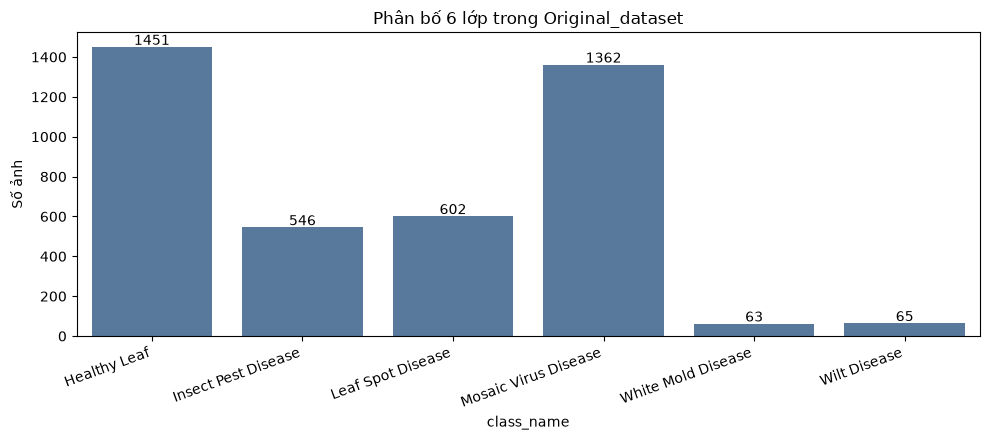

Nạp split đã lưu.
Train 2861 | Val 614 | Test 614  (không có ảnh trùng giữa các tập)


,train,val,test
class_name,,,
Healthy Leaf,1015,218,218
Insect Pest Disease,382,82,82
Leaf Spot Disease,422,90,90
Mosaic Virus Disease,953,204,205
White Mold Disease,44,10,9
Wilt Disease,45,10,10


Số ảnh train theo lớp: {'Healthy Leaf': 1015, 'Insect Pest Disease': 382, 'Leaf Spot Disease': 422, 'Mosaic Virus Disease': 953, 'White Mold Disease': 44, 'Wilt Disease': 45}


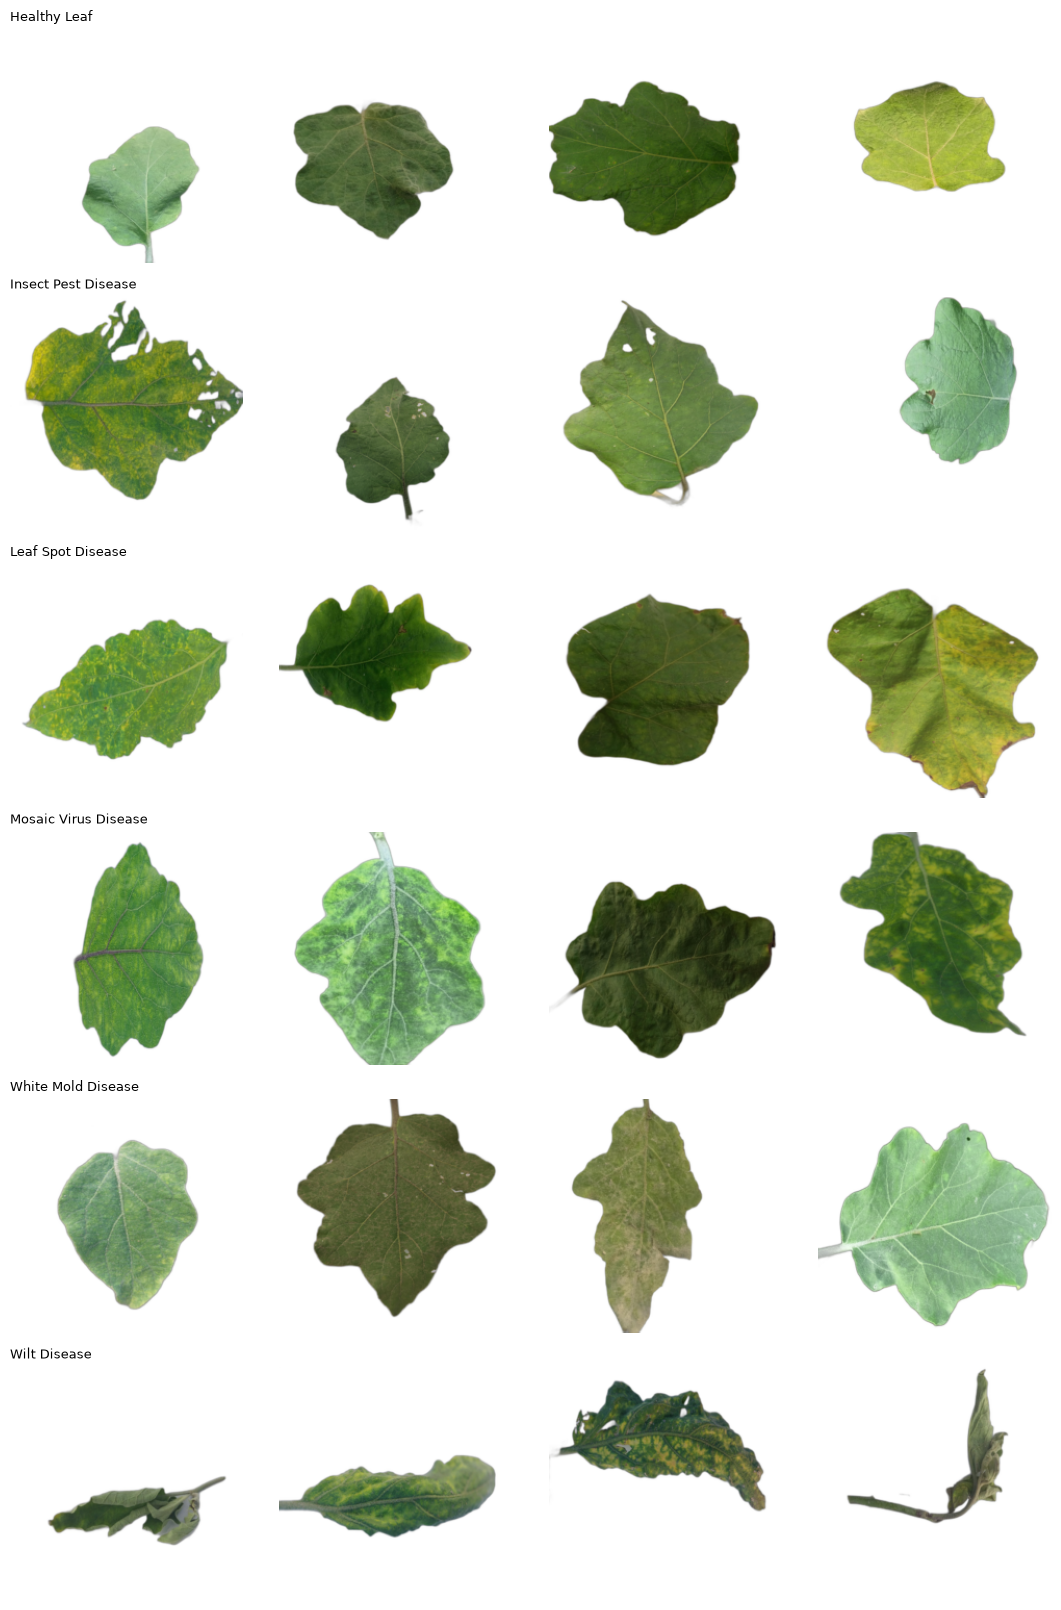

In [4]:
# ============================================================
# 3. EDA + split stratified cố định
# ============================================================
counts = df["class_name"].value_counts().reindex(CLASSES)
eda = pd.DataFrame({"count": counts, "percent": (counts / counts.sum() * 100).round(2)})
display(eda)
print("Tỉ lệ mất cân bằng (lớp đông nhất / lớp hiếm nhất): %.1f : 1" % (counts.max() / counts.min()))

fig, ax = plt.subplots(figsize=(10, 4.5))
sns.barplot(x=counts.index, y=counts.values, ax=ax, color="#4C78A8")
for i, v in enumerate(counts.values):
    ax.text(i, v + 10, str(v), ha="center")
ax.set_ylabel("Số ảnh")
ax.set_title("Phân bố 6 lớp trong Original_dataset")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "class_distribution.png", dpi=170)
plt.show()

split_files = {k: RESULTS_DIR / f"split6_{k}.csv" for k in ("train", "val", "test")}


def _load_split(path):
    s = pd.read_csv(path)
    return df.merge(s[["path"]], on="path", how="inner").reset_index(drop=True)


if all(p.exists() for p in split_files.values()) and RESUME:
    train_df, val_df, test_df = (_load_split(split_files[k]) for k in ("train", "val", "test"))
    ok = len(train_df) + len(val_df) + len(test_df) == len(df)
    print("Nạp split đã lưu." if ok else "Split cũ không khớp dữ liệu, tạo lại.")
else:
    ok = False

if not ok:
    dev_df, test_df = train_test_split(df, test_size=TEST_FRAC, stratify=df["label"], random_state=SEED)
    train_df, val_df = train_test_split(dev_df, test_size=VAL_FRAC / (1 - TEST_FRAC),
                                        stratify=dev_df["label"], random_state=SEED)
    train_df, val_df, test_df = (x.reset_index(drop=True) for x in (train_df, val_df, test_df))
    for k, x in zip(("train", "val", "test"), (train_df, val_df, test_df)):
        x[["path", "class_name", "label", "idx"]].to_csv(split_files[k], index=False)
    print("Đã tạo và lưu split mới.")

assert set(train_df.path).isdisjoint(val_df.path)
assert set(train_df.path).isdisjoint(test_df.path)
assert set(val_df.path).isdisjoint(test_df.path)
print(f"Train {len(train_df)} | Val {len(val_df)} | Test {len(test_df)}  (không có ảnh trùng giữa các tập)")

split_table = pd.DataFrame({
    "train": train_df["class_name"].value_counts().reindex(CLASSES),
    "val": val_df["class_name"].value_counts().reindex(CLASSES),
    "test": test_df["class_name"].value_counts().reindex(CLASSES),
})
display(split_table)


def as_split(d):
    return dict(idx=d["idx"].to_numpy(np.int64), y=d["label"].to_numpy(np.int64))


TR, VA, TE = as_split(train_df), as_split(val_df), as_split(test_df)
DEV = dict(idx=np.concatenate([TR["idx"], VA["idx"]]), y=np.concatenate([TR["y"], VA["y"]]))
TRAIN_COUNTS = np.bincount(TR["y"], minlength=NUM_CLASSES)
print("Số ảnh train theo lớp:", dict(zip(CLASSES, TRAIN_COUNTS.tolist())))

# Một vài ảnh mẫu
fig, axes = plt.subplots(NUM_CLASSES, 4, figsize=(11, 2.7 * NUM_CLASSES))
rng_vis = np.random.default_rng(SEED)
for r, cls in enumerate(CLASSES):
    sub = df[df["class_name"] == cls]
    pick = rng_vis.choice(len(sub), size=min(4, len(sub)), replace=False)
    for c in range(4):
        axes[r, c].axis("off")
        if c < len(pick):
            axes[r, c].imshow(XS[BASE_SIZE][int(sub.iloc[pick[c]]["idx"])])
            if c == 0:
                axes[r, c].set_title(cls, fontsize=9, loc="left")
plt.tight_layout()
plt.show()

## 4. Pipeline dữ liệu trên GPU: augmentation, MixUp/CutMix

Ảnh nằm trong RAM dưới dạng `uint8`. Mỗi batch được chuyển lên GPU, augment bằng các phép tensor (affine + `grid_sample`, color jitter, blur, nhiễu, random erasing), rồi chuẩn hoá ImageNet.

| Mức `aug` | Nội dung |
|---|---|
| `none` | không augment |
| `basic` | **đúng bộ augmentation trong notebook cũ của bạn**: flip ngang p=0.5, xoay ±15°, Gaussian blur σ∈[0,1], nhiễu Gaussian 0→0.05, brightness ×[0.8,1.2] (áp dụng online ngẫu nhiên mỗi epoch) |
| `strong` | crop ngẫu nhiên (diện tích 45–100%), flip ngang + dọc, xoay ±30°, color jitter (brightness/contrast/saturation), blur ngẫu nhiên, nhiễu, random erasing |

`mix_prob` bật **MixUp / CutMix** (chọn ngẫu nhiên 50/50 cho mỗi batch).

In [5]:
# ============================================================
# 4. Dữ liệu trên GPU: chuẩn hoá, augmentation, MixUp/CutMix
# ============================================================
MEAN_T = torch.tensor([0.485, 0.456, 0.406], device=DEVICE).view(1, 3, 1, 1)
STD_T = torch.tensor([0.229, 0.224, 0.225], device=DEVICE).view(1, 3, 1, 1)


def batch_to_device(X, idx):
    """X: mảng uint8 (N,H,W,3) trên CPU; idx: chỉ số -> tensor float [0,1] (B,3,H,W) trên GPU."""
    xb = torch.from_numpy(X[idx]).to(DEVICE, non_blocking=True)
    return xb.permute(0, 3, 1, 2).float().div_(255.0).contiguous()


def normalize(x):
    x = (x - MEAN_T) / STD_T
    if DEVICE.type == "cuda":
        x = x.contiguous(memory_format=torch.channels_last)
    return x


def _rand(B, lo, hi):
    if lo == hi:
        return torch.full((B,), float(lo), device=DEVICE)
    return torch.empty(B, device=DEVICE).uniform_(float(lo), float(hi))


def random_geometric(x, rot_deg=0.0, area=(1.0, 1.0), ratio=(1.0, 1.0), hflip=0.5, vflip=0.0):
    """Affine ngẫu nhiên theo từng mẫu: xoay + crop-zoom (diện tích/tỉ lệ) + tịnh tiến + flip."""
    B = x.size(0)
    ang = _rand(B, -rot_deg, rot_deg) * math.pi / 180.0
    a = _rand(B, area[0], area[1])
    r = torch.exp(_rand(B, math.log(ratio[0]), math.log(ratio[1])))
    w = torch.sqrt(a * r).clamp(max=1.0)
    h = torch.sqrt(a / r).clamp(max=1.0)
    tx = (torch.rand(B, device=DEVICE) * 2 - 1) * (1 - w)
    ty = (torch.rand(B, device=DEVICE) * 2 - 1) * (1 - h)
    fx = 1.0 - 2.0 * (torch.rand(B, device=DEVICE) < hflip).float()
    fy = 1.0 - 2.0 * (torch.rand(B, device=DEVICE) < vflip).float()
    c, s = torch.cos(ang), torch.sin(ang)
    theta = torch.zeros(B, 2, 3, device=DEVICE)
    theta[:, 0, 0] = c * w * fx
    theta[:, 0, 1] = -s * h * fy
    theta[:, 0, 2] = tx
    theta[:, 1, 0] = s * w * fx
    theta[:, 1, 1] = c * h * fy
    theta[:, 1, 2] = ty
    grid = F.affine_grid(theta, list(x.shape), align_corners=False)
    return F.grid_sample(x, grid, mode="bilinear", padding_mode="reflection", align_corners=False)


def gaussian_blur(x, sigma, k=7):
    """Blur Gaussian với sigma khác nhau cho từng mẫu (sigma=0 -> giữ nguyên)."""
    B, C, H, W = x.shape
    r = k // 2
    ax = torch.arange(-r, r + 1, device=x.device, dtype=x.dtype)
    ker = torch.exp(-(ax[None, :] ** 2) / (2 * sigma[:, None].clamp_min(1e-3) ** 2))
    ker = ker / ker.sum(1, keepdim=True)                               # (B,k)
    kx = ker.repeat_interleave(C, 0).view(B * C, 1, 1, k)
    ky = ker.repeat_interleave(C, 0).view(B * C, 1, k, 1)
    y = x.reshape(1, B * C, H, W)
    y = F.conv2d(F.pad(y, (r, r, 0, 0), mode="reflect"), kx, groups=B * C)
    y = F.conv2d(F.pad(y, (0, 0, r, r), mode="reflect"), ky, groups=B * C)
    return y.view(B, C, H, W)


def add_noise(x, max_std):
    std = _rand(x.size(0), 0.0, max_std).view(-1, 1, 1, 1)
    return (x + torch.randn_like(x) * std).clamp(0, 1)


def color_jitter(x, b=0.3, c=0.3, s=0.3):
    B = x.size(0)
    if b > 0:
        x = x * _rand(B, 1 - b, 1 + b).view(B, 1, 1, 1)
    if c > 0:
        m = x.mean(dim=(1, 2, 3), keepdim=True)
        x = (x - m) * _rand(B, 1 - c, 1 + c).view(B, 1, 1, 1) + m
    if s > 0:
        gray = 0.299 * x[:, 0:1] + 0.587 * x[:, 1:2] + 0.114 * x[:, 2:3]
        x = gray + (x - gray) * _rand(B, 1 - s, 1 + s).view(B, 1, 1, 1)
    return x.clamp(0, 1)


def random_erase(x, p=0.3, area=(0.02, 0.15), ratio=(0.3, 3.3)):
    B, C, H, W = x.shape
    on = torch.rand(B, device=DEVICE) < p
    a = _rand(B, area[0], area[1]) * H * W
    r = torch.exp(_rand(B, math.log(ratio[0]), math.log(ratio[1])))
    eh = torch.sqrt(a * r).clamp(max=H - 1)
    ew = torch.sqrt(a / r).clamp(max=W - 1)
    cy = torch.rand(B, device=DEVICE) * H
    cx = torch.rand(B, device=DEVICE) * W
    ys = torch.arange(H, device=DEVICE).view(1, H, 1).float()
    xs = torch.arange(W, device=DEVICE).view(1, 1, W).float()
    mask = ((ys - cy.view(B, 1, 1)).abs() < eh.view(B, 1, 1) / 2) & \
           ((xs - cx.view(B, 1, 1)).abs() < ew.view(B, 1, 1) / 2) & on.view(B, 1, 1)
    return torch.where(mask.unsqueeze(1), torch.rand_like(x), x)


def augment(x, level):
    B = x.size(0)
    if level == "none":
        return x
    if level == "basic":      # bộ augmentation cũ của người dùng
        x = random_geometric(x, rot_deg=15, hflip=0.5)
        x = gaussian_blur(x, _rand(B, 0.0, 1.0))
        x = add_noise(x, 0.05)
        return (x * _rand(B, 0.8, 1.2).view(B, 1, 1, 1)).clamp(0, 1)
    if level == "strong":
        x = random_geometric(x, rot_deg=30, area=(0.45, 1.0), ratio=(0.75, 4 / 3), hflip=0.5, vflip=0.5)
        x = color_jitter(x, 0.3, 0.3, 0.3)
        sig = _rand(B, 0.1, 1.5) * (torch.rand(B, device=DEVICE) < 0.3).float()
        x = gaussian_blur(x, sig)
        x = add_noise(x, 0.04)
        return random_erase(x, p=0.3)
    raise ValueError(f"aug không hợp lệ: {level}")


def apply_mix(x, y, cfg):
    """MixUp / CutMix theo batch. Trả về (x, y_a, y_b, lam)."""
    p = cfg["mix_prob"]
    if p <= 0 or x.size(0) < 2 or random.random() >= p:
        return x, y, y, 1.0
    perm = torch.randperm(x.size(0), device=x.device)
    if random.random() < 0.5:                                   # MixUp
        lam = float(np.random.beta(cfg["mixup_alpha"], cfg["mixup_alpha"]))
        return lam * x + (1 - lam) * x[perm], y, y[perm], lam
    lam = float(np.random.beta(cfg["cutmix_alpha"], cfg["cutmix_alpha"]))   # CutMix
    _, _, H, W = x.shape
    cut = math.sqrt(1 - lam)
    ch, cw = int(H * cut), int(W * cut)
    cy, cx = random.randint(0, H - 1), random.randint(0, W - 1)
    y1, y2 = max(cy - ch // 2, 0), min(cy + ch // 2, H)
    x1, x2 = max(cx - cw // 2, 0), min(cx + cw // 2, W)
    xp = x[perm]
    x = x.clone()
    x[:, :, y1:y2, x1:x2] = xp[:, :, y1:y2, x1:x2]
    lam = 1.0 - ((y2 - y1) * (x2 - x1) / float(H * W))
    return x, y, y[perm], lam


# Kiểm tra nhanh: augmentation giữ nguyên shape và dải giá trị
_t = torch.rand(4, 3, 64, 64, device=DEVICE)
for _lvl in ("none", "basic", "strong"):
    _o = augment(_t, _lvl)
    assert _o.shape == _t.shape and torch.isfinite(_o).all(), _lvl
print("Augmentation OK:", [l for l in ("none", "basic", "strong")])
del _t, _o

Augmentation OK: ['none', 'basic', 'strong']


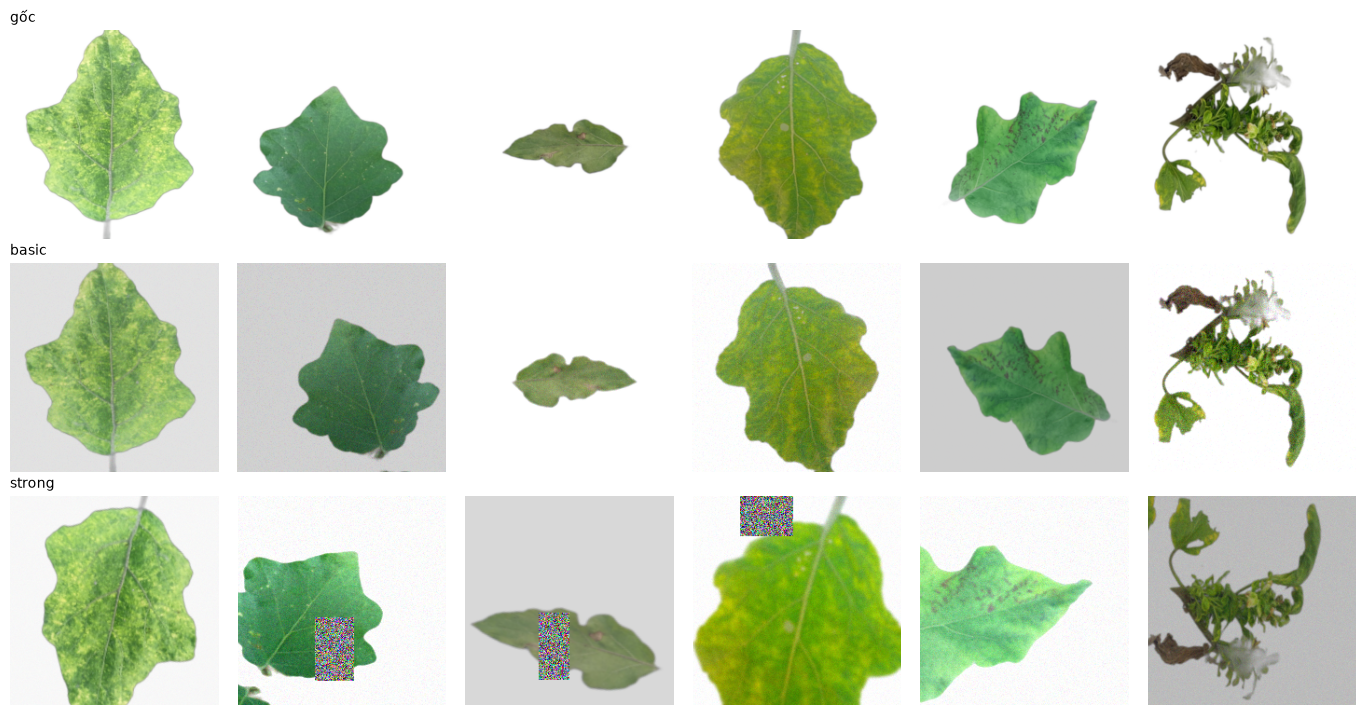

In [6]:
# ============================================================
# 4b. Xem thử augmentation (basic vs strong) trên vài ảnh train
# ============================================================
demo_idx = np.array([TR["idx"][np.where(TR["y"] == c)[0][0]] for c in range(NUM_CLASSES)])
base = batch_to_device(XS[BASE_SIZE], demo_idx)
set_seed(SEED)
views = {"gốc": base, "basic": augment(base, "basic"), "strong": augment(base, "strong")}
fig, axes = plt.subplots(3, NUM_CLASSES, figsize=(2.3 * NUM_CLASSES, 7.2))
for r, (name, t) in enumerate(views.items()):
    for c in range(NUM_CLASSES):
        axes[r, c].imshow(t[c].permute(1, 2, 0).clamp(0, 1).cpu().numpy())
        axes[r, c].axis("off")
        if c == 0:
            axes[r, c].set_title(name, loc="left", fontsize=10)
plt.tight_layout()
plt.show()
del base, views

## 5. Mô hình EfficientNet-B0

`build_model(cfg)` tạo EfficientNet-B0 của torchvision với hai kiểu head:

* **`paper`**: `GAP → Linear(1280→hidden) → ReLU → Dropout → Linear(hidden→6)`, head dùng trong các notebook trước. Được dùng ở A, B, C.
* **`msf_gem`** (đề xuất cho D): **Multi-Scale Fusion + GeM pooling**. Lấy feature map từ stage 5, 6, 7, 8 (112 / 192 / 320 / 1280 kênh) → mỗi nhánh qua **GeM pooling** (learnable *p*, giữ tín hiệu của vùng bệnh nhỏ tốt hơn average pooling) → nối lại (1904 chiều) → LayerNorm → MLP. Ý tưởng: triệu chứng bệnh lá thường là chi tiết nhỏ, nên đặc trưng ở độ phân giải trung gian rất hữu ích; ngoài ra còn tăng **stochastic depth** (`drop_path`).

Các tham số `unfreeze` (`all / from3 / from5 / from6 / head`) và `bn_mode` (`train / freeze`) điều khiển phần nào được fine-tune.

In [7]:
# ============================================================
# 5. Mô hình
# ============================================================
class GeM(nn.Module):
    """Generalized-Mean pooling với p học được (p=1: average, p→∞: max)."""
    def __init__(self, p=3.0, eps=1e-6):
        super().__init__()
        self.p = nn.Parameter(torch.ones(1) * p)
        self.eps = eps

    def forward(self, x):
        p = self.p.clamp(min=1.0)
        x = x.float().clamp(min=self.eps).pow(p)
        return F.avg_pool2d(x, x.shape[-2:]).pow(1.0 / p).flatten(1)


class MSFHead(nn.Module):
    """Multi-scale fusion head: GeM trên nhiều stage -> nối -> LayerNorm -> MLP."""
    def __init__(self, chans, hidden, num_classes, dropout):
        super().__init__()
        self.pools = nn.ModuleList([GeM() for _ in chans])
        d = int(sum(chans))
        self.norm = nn.LayerNorm(d)
        self.drop1 = nn.Dropout(dropout * 0.5)
        self.fc1 = nn.Linear(d, hidden)
        self.act = nn.SiLU()
        self.drop2 = nn.Dropout(dropout)
        self.fc2 = nn.Linear(hidden, num_classes)

    def forward(self, feats):
        z = torch.cat([pool(f) for pool, f in zip(self.pools, feats)], dim=1)
        z = self.norm(z)
        z = self.drop2(self.act(self.fc1(self.drop1(z))))
        return self.fc2(z)


MSF_STAGES = (5, 6, 7, 8)
MSF_CHANNELS = (112, 192, 320, 1280)


class EffNetB0Net(nn.Module):
    def __init__(self, pretrained=True, num_classes=NUM_CLASSES, head_type="paper",
                 hidden_dim=256, dropout=0.5, drop_path=0.2):
        super().__init__()
        weights = EfficientNet_B0_Weights.DEFAULT if pretrained else None
        base = models.efficientnet_b0(weights=weights, stochastic_depth_prob=float(drop_path))
        self.features = base.features
        self.avgpool = base.avgpool
        self.head_type = head_type
        if head_type == "paper":
            self.classifier = nn.Sequential(
                nn.Linear(1280, int(hidden_dim)), nn.ReLU(inplace=True),
                nn.Dropout(float(dropout)), nn.Linear(int(hidden_dim), num_classes))
        elif head_type == "msf_gem":
            self.classifier = MSFHead(MSF_CHANNELS, int(hidden_dim), num_classes, float(dropout))
        else:
            raise ValueError(head_type)

    def forward(self, x):
        if self.head_type == "paper":
            x = self.avgpool(self.features(x))
            return self.classifier(torch.flatten(x, 1))
        feats = []
        for i, layer in enumerate(self.features):
            x = layer(x)
            if i in MSF_STAGES:
                feats.append(x)
        return self.classifier(feats)


UNFREEZE_MIN = {"all": 0, "from3": 3, "from5": 5, "from6": 6, "head": 9}


def apply_freezing(model, unfreeze):
    mi = UNFREEZE_MIN[unfreeze]
    for i, blk in enumerate(model.features):
        for p in blk.parameters():
            p.requires_grad = i >= mi


def set_bn_mode(model, unfreeze, bn_mode):
    """Gọi sau model.train(): BN của stage bị đóng băng (hoặc bn_mode='freeze') luôn ở eval."""
    mi = UNFREEZE_MIN[unfreeze]
    for i, blk in enumerate(model.features):
        if i < mi or bn_mode == "freeze":
            for m in blk.modules():
                if isinstance(m, nn.BatchNorm2d):
                    m.eval()


def build_model(cfg):
    model = EffNetB0Net(pretrained=cfg["pretrained"], head_type=cfg["head_type"],
                        hidden_dim=cfg["hidden_dim"], dropout=cfg["dropout"],
                        drop_path=cfg["drop_path"])
    if not cfg["pretrained"] and cfg["unfreeze"] != "all":
        raise ValueError("Train from scratch bắt buộc unfreeze='all'")
    apply_freezing(model, cfg["unfreeze"])
    model = model.to(DEVICE)
    if DEVICE.type == "cuda":
        model = model.to(memory_format=torch.channels_last)
    return model


def count_params(model):
    tot = sum(p.numel() for p in model.parameters())
    trn = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return tot, trn


# Kiểm tra shape cho cả hai head
for _head in ("paper", "msf_gem"):
    _c = dict(pretrained=False, head_type=_head, hidden_dim=128, dropout=0.3, drop_path=0.2, unfreeze="all")
    _m = build_model(_c).eval()
    with torch.no_grad():
        _o = _m(torch.zeros(2, 3, 224, 224, device=DEVICE))
    t, tr_ = count_params(_m)
    print(f"head={_head:8s} -> logits {tuple(_o.shape)} | tham số {t:,} (trainable {tr_:,})")
    del _m, _o

head=paper    -> logits (2, 6) | tham số 4,172,290 (trainable 4,172,290)
head=msf_gem  -> logits (2, 6) | tham số 4,255,974 (trainable 4,255,974)


## 6. Hàm loss xử lý mất cân bằng và sampler

| `loss_type` | Mô tả |
|---|---|
| `ce` | Cross-Entropy thường (hỗ trợ `label_smoothing`) |
| `weighted_ce` | CE với trọng số lớp `(N / (K·n_c))^p` (`class_weight_power = p`) |
| `cb_ce` | CE theo **Class-Balanced weights** (Cui et al., 2019): `(1-β)/(1-β^{n_c})` |
| `focal` | Focal Loss `(1-p_t)^γ` |
| `weighted_focal` | Focal Loss + trọng số lớp |
| `cb_focal` | Focal Loss + Class-Balanced weights |

`sampling`: `none` (xáo trộn thường), `sqrt` (lấy mẫu với xác suất ∝ 1/√n_c), `balanced` (∝ 1/n_c, oversample lớp hiếm mạnh nhất).

In [8]:
# ============================================================
# 6. Loss + sampler cho dữ liệu mất cân bằng
# ============================================================
def class_weights_from_counts(counts, loss_type, power=0.5, cb_beta=0.999):
    counts = np.maximum(np.asarray(counts, dtype=np.float64), 1.0)
    if loss_type in ("weighted_ce", "weighted_focal"):
        w = (counts.sum() / (len(counts) * counts)) ** power
    elif loss_type in ("cb_ce", "cb_focal"):
        w = (1.0 - cb_beta) / (1.0 - np.power(cb_beta, counts))
    else:
        return None
    return torch.tensor(w / w.mean(), dtype=torch.float32)


class ImbalanceLoss(nn.Module):
    def __init__(self, loss_type, counts, power=0.5, gamma=2.0, label_smoothing=0.0, cb_beta=0.999):
        super().__init__()
        if loss_type not in ("ce", "weighted_ce", "cb_ce", "focal", "weighted_focal", "cb_focal"):
            raise ValueError(loss_type)
        self.focal = loss_type.endswith("focal")
        self.gamma = float(gamma)
        self.ls = 0.0 if self.focal else float(label_smoothing)
        w = class_weights_from_counts(counts, loss_type, power, cb_beta)
        self.use_w = w is not None
        self.register_buffer("w", w if w is not None else torch.ones(len(counts)))

    def forward(self, logits, y):
        logits = logits.float()
        if not self.focal:
            return F.cross_entropy(logits, y, weight=self.w if self.use_w else None,
                                   label_smoothing=self.ls)
        logpt = F.log_softmax(logits, dim=1).gather(1, y[:, None]).squeeze(1)
        pt = logpt.exp()
        loss = -((1.0 - pt).clamp(min=0.0) ** self.gamma) * logpt
        if self.use_w:
            loss = loss * self.w[y]
        return loss.mean()


def epoch_order(y, strategy, rng):
    n = len(y)
    if strategy == "none":
        return rng.permutation(n)
    cnt = np.bincount(y, minlength=NUM_CLASSES).astype(np.float64)
    per_class = 1.0 / np.sqrt(np.maximum(cnt, 1)) if strategy == "sqrt" else 1.0 / np.maximum(cnt, 1)
    p = per_class[y]
    return rng.choice(n, size=n, replace=True, p=p / p.sum())


print("Trọng số lớp (train) theo từng loại loss:")
rows = {}
for lt, pw in [("weighted_ce", 0.5), ("weighted_ce", 1.0), ("cb_focal", 0.0)]:
    w = class_weights_from_counts(TRAIN_COUNTS, lt, power=pw, cb_beta=0.999)
    rows[f"{lt}(p={pw})"] = np.round(w.numpy(), 3)
display(pd.DataFrame(rows, index=CLASSES))

_l = ImbalanceLoss("weighted_focal", TRAIN_COUNTS).to(DEVICE)
assert torch.isfinite(_l(torch.randn(8, NUM_CLASSES, device=DEVICE), torch.randint(0, NUM_CLASSES, (8,), device=DEVICE)))
del _l

Trọng số lớp (train) theo từng loại loss:


,weighted_ce(p=0.5),weighted_ce(p=1.0),cb_focal(p=0.0)
Healthy Leaf,0.406,0.114,0.170
Insect Pest Disease,0.662,0.302,0.342
Leaf Spot Disease,0.630,0.274,0.316
Mosaic Virus Disease,0.419,0.121,0.177
White Mold Disease,1.952,2.624,2.525
Wilt Disease,1.930,2.566,2.470


## 7. Engine huấn luyện

`train_model(cfg, tr, va)` làm đúng những việc sau:

* optimizer: `adamw / adam / sgd(nesterov) / rmsprop`, tuỳ chọn **SAM** (`sam_rho > 0`, tối thiểu hoá sharpness, thường giúp tổng quát hoá tốt hơn) và **layer-wise LR decay** (`lr_decay < 1`);
* scheduler: `cosine` (warmup + cosine, bước theo iteration) hoặc `plateau`;
* loss/sampler theo phần 6, MixUp/CutMix theo phần 4;
* **EMA** của trọng số (`ema_decay > 0`);
* mỗi epoch đánh giá trên validation, **chọn checkpoint theo val accuracy** (macro-F1 → val-loss làm tie-break), early stopping theo `patience`.

`train_or_load(tag, ...)` bọc ngoài để lưu/nạp checkpoint (resume).

In [9]:
# ============================================================
# 7. Engine huấn luyện
# ============================================================
DEFAULT_CFG = dict(
    # kiến trúc
    pretrained=True, img_size=224, head_type="paper", hidden_dim=256, dropout=0.5, drop_path=0.2,
    unfreeze="all", bn_mode="train",
    # tối ưu
    optimizer="adamw", backbone_lr=1e-4, head_lr=1e-3, weight_decay=1e-4, lr_decay=1.0,
    sam_rho=0.0, grad_clip=1.0,
    scheduler="cosine", warmup_epochs=2, plateau_factor=0.3, plateau_patience=3,
    batch_size=32, epochs=40, patience=12,
    # loss / imbalance
    loss_type="ce", class_weight_power=0.5, focal_gamma=2.0, label_smoothing=0.0, cb_beta=0.999,
    sampling="none",
    # dữ liệu
    aug="basic", mix_prob=0.0, mixup_alpha=0.4, cutmix_alpha=1.0,
    # khác
    ema_decay=0.0,
)


def _py(v):
    if isinstance(v, np.generic):
        return v.item()
    if isinstance(v, (list, tuple)):
        return type(v)(_py(i) for i in v)
    return v


def full_cfg(cfg):
    out = {**DEFAULT_CFG, **{k: _py(v) for k, v in cfg.items()}}
    unknown = set(cfg) - set(DEFAULT_CFG)
    if unknown:
        raise KeyError(f"cfg có khoá lạ: {unknown}")
    return out


class ModelEMA:
    def __init__(self, model, decay):
        self.module = copy.deepcopy(model).eval()
        for p in self.module.parameters():
            p.requires_grad_(False)
        self.decay = decay
        self.n = 0

    @torch.no_grad()
    def update(self, model):
        self.n += 1
        d = min(self.decay, (1 + self.n) / (10 + self.n))
        msd = model.state_dict()
        for k, v in self.module.state_dict().items():
            if v.dtype.is_floating_point:
                v.mul_(d).add_(msd[k].detach(), alpha=1.0 - d)
            else:
                v.copy_(msd[k])


def make_optimizer(model, cfg):
    L = len(model.features)
    groups = []
    for i, blk in enumerate(model.features):
        ps = [p for p in blk.parameters() if p.requires_grad]
        if ps:
            groups.append({"params": ps, "lr": cfg["backbone_lr"] * (cfg["lr_decay"] ** (L - 1 - i))})
    hp = [p for p in model.classifier.parameters() if p.requires_grad]
    groups.append({"params": hp, "lr": cfg["head_lr"]})
    name, wd = cfg["optimizer"], cfg["weight_decay"]
    mult = {"sgd": 20.0, "rmsprop": 0.5}.get(name, 1.0)      # SGD cần lr lớn hơn Adam
    for g in groups:
        g["lr"] *= mult
    if name == "adamw":
        return torch.optim.AdamW(groups, weight_decay=wd, betas=(0.9, 0.999), eps=1e-8)
    if name == "adam":
        return torch.optim.Adam(groups, weight_decay=wd, betas=(0.9, 0.999), eps=1e-8)
    if name == "sgd":
        return torch.optim.SGD(groups, momentum=0.9, nesterov=True, weight_decay=wd)
    if name == "rmsprop":
        return torch.optim.RMSprop(groups, alpha=0.99, eps=1e-6, momentum=0.9, weight_decay=wd)
    raise ValueError(name)


def tta_views(x, n):
    v = [x]
    if n >= 2:
        v.append(x.flip(3))
    if n >= 4:
        v += [x.flip(2), x.flip(2).flip(3)]
    if n >= 8:
        t = x.transpose(2, 3)
        v += [t, t.flip(3), t.flip(2), t.flip(2).flip(3)]
    if DEVICE.type == "cuda":
        v = [a.contiguous(memory_format=torch.channels_last) for a in v]
    return v


@torch.no_grad()
def predict_probs(model, X, idx, tta=1, bs=64):
    """Xác suất softmax (N, K), có thể TTA (1, 2, 4 hoặc 8 view)."""
    model.eval()
    out = []
    for s in range(0, len(idx), bs):
        xb = normalize(batch_to_device(X, idx[s:s + bs]))
        acc = 0
        views = tta_views(xb, tta)
        for v in views:
            with torch.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=USE_AMP):
                logits = model(v)
            acc = acc + torch.softmax(logits.float(), dim=1)
        out.append((acc / len(views)).cpu())
    return torch.cat(out).numpy()


def compute_metrics(y_true, probs):
    pred = probs.argmax(1)
    p, r, f, _ = precision_recall_fscore_support(y_true, pred, average="macro", zero_division=0)
    nll = float(-np.log(np.clip(probs[np.arange(len(y_true)), y_true], 1e-9, 1.0)).mean())
    return dict(
        accuracy=float(accuracy_score(y_true, pred)),
        balanced_accuracy=float(balanced_accuracy_score(y_true, pred)),
        macro_precision=float(p), macro_recall=float(r), macro_f1=float(f),
        weighted_f1=float(f1_score(y_true, pred, average="weighted", zero_division=0)),
        nll=nll,
    )


def train_model(cfg, tr, va, tag="", verbose=1, seed=SEED):
    cfg = full_cfg(cfg)
    set_seed(seed)
    rng = np.random.default_rng(seed)
    X_tr, X_va = XS[cfg["img_size"]], XS[cfg["img_size"]]

    model = build_model(cfg)
    total_p, train_p = count_params(model)
    crit = ImbalanceLoss(cfg["loss_type"], np.bincount(tr["y"], minlength=NUM_CLASSES),
                         cfg["class_weight_power"], cfg["focal_gamma"],
                         cfg["label_smoothing"], cfg["cb_beta"]).to(DEVICE)
    optimizer = make_optimizer(model, cfg)
    trainable = [p for p in model.parameters() if p.requires_grad]

    n, bs = len(tr["y"]), int(cfg["batch_size"])
    steps_per_epoch = math.ceil(n / bs)
    total_steps = cfg["epochs"] * steps_per_epoch
    warm = cfg["warmup_epochs"] * steps_per_epoch
    if cfg["scheduler"] == "cosine":
        def lr_lambda(step):
            if step < warm:
                return (step + 1) / max(1, warm)
            prog = min(1.0, (step - warm) / max(1, total_steps - warm))
            return 0.01 + 0.99 * 0.5 * (1.0 + math.cos(math.pi * prog))
        sched = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)
    else:
        sched = torch.optim.lr_scheduler.ReduceLROnPlateau(
            optimizer, mode="max", factor=cfg["plateau_factor"], patience=cfg["plateau_patience"], min_lr=1e-7)

    sam = cfg["sam_rho"] > 0
    amp_on = USE_AMP
    use_scaler = amp_on and AMP_DTYPE == torch.float16
    if sam and use_scaler:                       # SAM + fp16 scaler phức tạp -> dùng fp32 cho an toàn
        amp_on, use_scaler = False, False
    scaler = torch.amp.GradScaler("cuda", enabled=use_scaler)
    ema = ModelEMA(model, cfg["ema_decay"]) if cfg["ema_decay"] > 0 else None

    hist = {k: [] for k in ("epoch", "train_loss", "train_acc", "val_acc", "val_f1", "val_nll", "lr_head", "seconds")}
    best = dict(acc=-1.0, f1=-1.0, nll=1e9, epoch=0, state=None, metrics=None)
    bad_epochs, t_start = 0, time.time()

    def fwd_loss(xn, ya, yb, lam):
        with torch.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=amp_on):
            logits = model(xn)
        logits = logits.float()
        loss = crit(logits, ya) if lam >= 1.0 else lam * crit(logits, ya) + (1 - lam) * crit(logits, yb)
        return logits, loss

    for epoch in range(1, cfg["epochs"] + 1):
        t_ep = time.time()
        model.train()
        set_bn_mode(model, cfg["unfreeze"], cfg["bn_mode"])
        order = epoch_order(tr["y"], cfg["sampling"], rng)
        run_loss, run_correct, seen = 0.0, 0, 0

        for s in range(0, n, bs):
            sel = order[s:s + bs]
            if len(sel) < 2:
                continue
            x = batch_to_device(X_tr, tr["idx"][sel])
            y = torch.from_numpy(tr["y"][sel]).to(DEVICE)
            x = augment(x, cfg["aug"])
            x, ya, yb, lam = apply_mix(x, y, cfg)
            xn = normalize(x)

            optimizer.zero_grad(set_to_none=True)
            logits, loss = fwd_loss(xn, ya, yb, lam)
            if use_scaler:
                scaler.scale(loss).backward()
            else:
                loss.backward()

            if sam:                                           # Sharpness-Aware Minimization
                params = [p for g in optimizer.param_groups for p in g["params"] if p.grad is not None]
                gnorm = torch.norm(torch.stack([p.grad.detach().norm(2) for p in params]), 2)
                scale = cfg["sam_rho"] / (gnorm + 1e-12)
                eps_list = []
                with torch.no_grad():
                    for p in params:
                        e = p.grad * scale
                        p.add_(e)
                        eps_list.append(e)
                optimizer.zero_grad(set_to_none=True)
                _, loss2 = fwd_loss(xn, ya, yb, lam)
                loss2.backward()
                with torch.no_grad():
                    for p, e in zip(params, eps_list):
                        p.sub_(e)

            if use_scaler:
                scaler.unscale_(optimizer)
            if cfg["grad_clip"] > 0:
                torch.nn.utils.clip_grad_norm_(trainable, cfg["grad_clip"])
            if use_scaler:
                scaler.step(optimizer)
                scaler.update()
            else:
                optimizer.step()
            if cfg["scheduler"] == "cosine":
                sched.step()
            if ema is not None:
                ema.update(model)

            run_loss += float(loss.item()) * len(sel)
            run_correct += int((logits.argmax(1) == ya).sum().item())
            seen += len(sel)

        eval_model = ema.module if ema is not None else model
        pv = predict_probs(eval_model, X_va, va["idx"], tta=1)
        m = compute_metrics(va["y"], pv)
        if cfg["scheduler"] != "cosine":
            sched.step(m["accuracy"])

        hist["epoch"].append(epoch)
        hist["train_loss"].append(run_loss / max(1, seen))
        hist["train_acc"].append(run_correct / max(1, seen))
        hist["val_acc"].append(m["accuracy"])
        hist["val_f1"].append(m["macro_f1"])
        hist["val_nll"].append(m["nll"])
        hist["lr_head"].append(optimizer.param_groups[-1]["lr"])
        hist["seconds"].append(time.time() - t_ep)

        improved = (m["accuracy"] > best["acc"] + 1e-6) or (
            abs(m["accuracy"] - best["acc"]) <= 1e-6 and
            (m["macro_f1"] > best["f1"] + 1e-6 or
             (abs(m["macro_f1"] - best["f1"]) <= 1e-6 and m["nll"] < best["nll"])))
        if improved:
            best.update(acc=m["accuracy"], f1=m["macro_f1"], nll=m["nll"], epoch=epoch, metrics=m,
                        state={k: v.detach().cpu().clone() for k, v in eval_model.state_dict().items()})
            bad_epochs = 0
        else:
            bad_epochs += 1

        if verbose >= 2 or (verbose == 1 and (epoch <= 2 or epoch % 5 == 0)):
            print(f"  [{tag}] ep {epoch:03d}/{cfg['epochs']} | loss {hist['train_loss'][-1]:.4f} "
                  f"| val_acc {m['accuracy']:.4f} | val_f1 {m['macro_f1']:.4f} "
                  f"| best {best['acc']:.4f}@{best['epoch']} | {hist['seconds'][-1]:.1f}s")
        if bad_epochs >= cfg["patience"]:
            if verbose:
                print(f"  [{tag}] early stopping tại epoch {epoch} (best epoch {best['epoch']}).")
            break

    final = ema.module if ema is not None else model
    final.load_state_dict(best["state"])
    final.eval()
    if ema is not None:
        del model
    del optimizer, sched, crit
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
    if verbose:
        print(f"  [{tag}] xong: best val_acc={best['acc']:.4f} (epoch {best['epoch']}), "
              f"{(time.time() - t_start) / 60:.1f} phút, params {total_p:,} (trainable {train_p:,})")
    return dict(model=final, history=hist, best_epoch=best["epoch"], val=best["metrics"],
                seconds=time.time() - t_start, cfg=cfg, n_params=total_p)


def train_or_load(tag, cfg, tr, va, verbose=1, seed=SEED):
    ckpt = MODELS_DIR / f"{tag}.pt"
    if RESUME and ckpt.exists():
        blob = torch.load(ckpt, map_location="cpu", weights_only=False)
        model = build_model({**blob["cfg"], "pretrained": False})
        model.load_state_dict(blob["state"])
        model.eval()
        print(f"[{tag}] nạp checkpoint đã có: {ckpt.name} (val_acc={blob['val']['accuracy']:.4f})")
        return dict(model=model, history=blob["history"], best_epoch=blob["best_epoch"],
                    val=blob["val"], seconds=blob["seconds"], cfg=blob["cfg"], n_params=blob.get("n_params", 0))
    res = train_model(cfg, tr, va, tag=tag, verbose=verbose, seed=seed)
    torch.save(dict(state=res["model"].state_dict(), cfg=res["cfg"], history=res["history"],
                    best_epoch=res["best_epoch"], val=res["val"], seconds=res["seconds"],
                    n_params=res["n_params"]), ckpt)
    return res


def free_memory():
    gc.collect()
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()


print("Engine sẵn sàng.")

Engine sẵn sàng.


## 8. Hàm đánh giá, vẽ biểu đồ, bootstrap CI

* `evaluate_result` đánh giá trên **test** (một view và TTA×8) và lưu vào `RESULTS`.
* `bootstrap_ci` cho khoảng tin cậy 95% của accuracy: test chỉ ~600 ảnh nên chênh lệch dưới ±2% giữa hai mô hình **chưa đủ để kết luận**.

In [10]:
# ============================================================
# 8. Đánh giá / biểu đồ
# ============================================================
RESULTS = {}


def bootstrap_ci(y_true, pred, n_boot=2000, seed=SEED):
    rng = np.random.default_rng(seed)
    n = len(y_true)
    accs = np.array([(y_true[i] == pred[i]).mean() for i in rng.integers(0, n, size=(n_boot, n))])
    return float(np.percentile(accs, 2.5)), float(np.percentile(accs, 97.5))


def register_result(name, probs_1, probs_tta, extra=None):
    y = TE["y"]
    RESULTS[name] = dict(
        probs=probs_1, probs_tta=probs_tta,
        metrics=compute_metrics(y, probs_1), metrics_tta=compute_metrics(y, probs_tta),
        ci=bootstrap_ci(y, probs_1.argmax(1)), ci_tta=bootstrap_ci(y, probs_tta.argmax(1)),
        extra=extra or {})


def plot_confusion(y_true, pred, title, fname=None):
    cm = confusion_matrix(y_true, pred, labels=np.arange(NUM_CLASSES))
    cmn = cm / np.maximum(cm.sum(1, keepdims=True), 1)
    fig, axes = plt.subplots(1, 2, figsize=(15, 5.8))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES,
                ax=axes[0], cbar=False)
    axes[0].set_title(title + " — số lượng")
    sns.heatmap(cmn, annot=True, fmt=".2f", cmap="Greens", vmin=0, vmax=1, xticklabels=CLASSES,
                yticklabels=CLASSES, ax=axes[1], cbar=False)
    axes[1].set_title(title + " — recall theo hàng")
    for ax in axes:
        ax.set_xlabel("Dự đoán")
        ax.set_ylabel("Thực tế")
        ax.tick_params(axis="x", rotation=35)
    plt.tight_layout()
    if fname:
        plt.savefig(RESULTS_DIR / fname, dpi=160, bbox_inches="tight")
    plt.show()
    return cm


def show_report(name, use_tta=False, plot=True):
    r = RESULTS[name]
    probs = r["probs_tta"] if use_tta else r["probs"]
    pred = probs.argmax(1)
    rep = pd.DataFrame(classification_report(TE["y"], pred, labels=np.arange(NUM_CLASSES),
                                             target_names=CLASSES, output_dict=True, zero_division=0)).T
    display(rep.round(4))
    rep.to_csv(RESULTS_DIR / f"{name}_{'tta' if use_tta else 'single'}_report.csv")
    if plot:
        plot_confusion(TE["y"], pred, f"{name}" + (" (TTA×8)" if use_tta else ""),
                       f"{name}_{'tta' if use_tta else 'single'}_confusion.png")
    return rep


def evaluate_result(name, res, tta=8, plot=True):
    size = res["cfg"]["img_size"]
    p1 = predict_probs(res["model"], XS[size], TE["idx"], tta=1)
    pt = predict_probs(res["model"], XS[size], TE["idx"], tta=tta)
    register_result(name, p1, pt, extra=dict(best_epoch=res["best_epoch"], val=res["val"],
                                              seconds=res["seconds"], cfg=res["cfg"]))
    m, mt = RESULTS[name]["metrics"], RESULTS[name]["metrics_tta"]
    print(f"\n=== {name} — TEST ===")
    print(f"  1 view : acc={m['accuracy']:.4f}  (95% CI {RESULTS[name]['ci'][0]:.3f}–{RESULTS[name]['ci'][1]:.3f})  "
          f"macro-F1={m['macro_f1']:.4f}  balanced-acc={m['balanced_accuracy']:.4f}")
    print(f"  TTA x{tta}: acc={mt['accuracy']:.4f}  (95% CI {RESULTS[name]['ci_tta'][0]:.3f}–{RESULTS[name]['ci_tta'][1]:.3f})  "
          f"macro-F1={mt['macro_f1']:.4f}  balanced-acc={mt['balanced_accuracy']:.4f}")
    show_report(name, use_tta=False, plot=plot)
    return RESULTS[name]


def plot_history(res, title, fname=None):
    h = pd.DataFrame(res["history"])
    fig, axes = plt.subplots(1, 3, figsize=(16, 4))
    axes[0].plot(h["epoch"], h["train_loss"], label="train loss")
    axes[0].set_title(title + " — train loss (có thể gồm MixUp/CutMix)")
    axes[1].plot(h["epoch"], h["train_acc"], label="train acc")
    axes[1].plot(h["epoch"], h["val_acc"], label="val acc")
    axes[1].axvline(res["best_epoch"], color="gray", ls="--", lw=1)
    axes[1].set_title("accuracy")
    axes[2].plot(h["epoch"], h["val_f1"], label="val macro-F1", color="tab:green")
    axes[2].plot(h["epoch"], h["lr_head"] / max(h["lr_head"].max(), 1e-12), label="lr (chuẩn hoá)", color="tab:orange")
    axes[2].set_title("val macro-F1 / lr")
    for ax in axes:
        ax.set_xlabel("epoch")
        ax.grid(alpha=0.25)
        ax.legend()
    plt.tight_layout()
    if fname:
        plt.savefig(RESULTS_DIR / fname, dpi=160, bbox_inches="tight")
    plt.show()


def cfg_diff(cfg):
    full = full_cfg(cfg)
    return {k: v for k, v in full.items() if v != DEFAULT_CFG[k]}


print("Helper đánh giá sẵn sàng.")

Helper đánh giá sẵn sàng.


# Experiment A — EfficientNet-B0 **pretrained ImageNet** (fine-tune toàn mạng)

Baseline chuẩn: nạp trọng số ImageNet, thay head 6 lớp, fine-tune **toàn bộ** mạng với AdamW, Cross-Entropy thường, cosine schedule + warmup, augmentation `basic`.

Khác với các notebook cũ (đóng băng toàn bộ hoặc một phần backbone, không augmentation online), bản này fine-tune toàn mạng và augment online. Lý do: trong các lần search trước, train score lên tới ~0.92–0.97 trong khi validation macro-F1 chỉ ~0.74, tức là mô hình overfit khá nặng.

Cấu hình A (khác mặc định): {}
[A_pretrained] nạp checkpoint đã có: A_pretrained.pt (val_acc=0.7508)


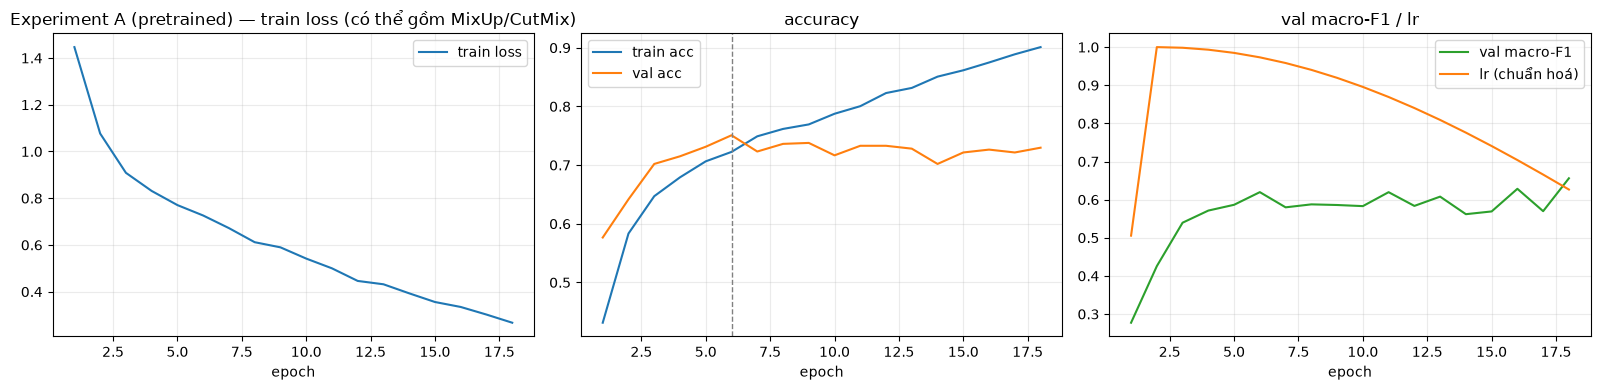

In [11]:
# ============================================================
# Experiment A — pretrained, fine-tune toàn mạng, CE thường
# ============================================================
cfg_A = dict(
    pretrained=True, img_size=BASE_SIZE, head_type="paper", hidden_dim=256, dropout=0.5,
    unfreeze="all", bn_mode="train",
    optimizer="adamw", backbone_lr=1e-4, head_lr=1e-3, weight_decay=1e-4,
    scheduler="cosine", warmup_epochs=2,
    batch_size=32, epochs=BUDGET["A_epochs"], patience=12,
    loss_type="ce", sampling="none", aug="basic",
)
print("Cấu hình A (khác mặc định):", cfg_diff(cfg_A))
res_A = train_or_load("A_pretrained", cfg_A, TR, VA, verbose=1)
plot_history(res_A, "Experiment A (pretrained)", "A_history.png")


=== A_pretrained — TEST ===
  1 view : acc=0.6971  (95% CI 0.660–0.731)  macro-F1=0.5388  balanced-acc=0.5454
  TTA x8: acc=0.7101  (95% CI 0.673–0.746)  macro-F1=0.5705  balanced-acc=0.5678


,precision,recall,f1-score,support
Healthy Leaf,0.6679,0.8486,0.7475,218.0000
Insect Pest Disease,0.6744,0.7073,0.6905,82.0000
Leaf Spot Disease,0.6500,0.4333,0.5200,90.0000
Mosaic Virus Disease,0.7821,0.6829,0.7292,205.0000
White Mold Disease,0.0000,0.0000,0.0000,9.0000
Wilt Disease,0.5000,0.6000,0.5455,10.0000
accuracy,0.6971,0.6971,0.6971,0.6971
macro avg,0.5457,0.5454,0.5388,614.0000
weighted avg,0.6917,0.6971,0.6862,614.0000


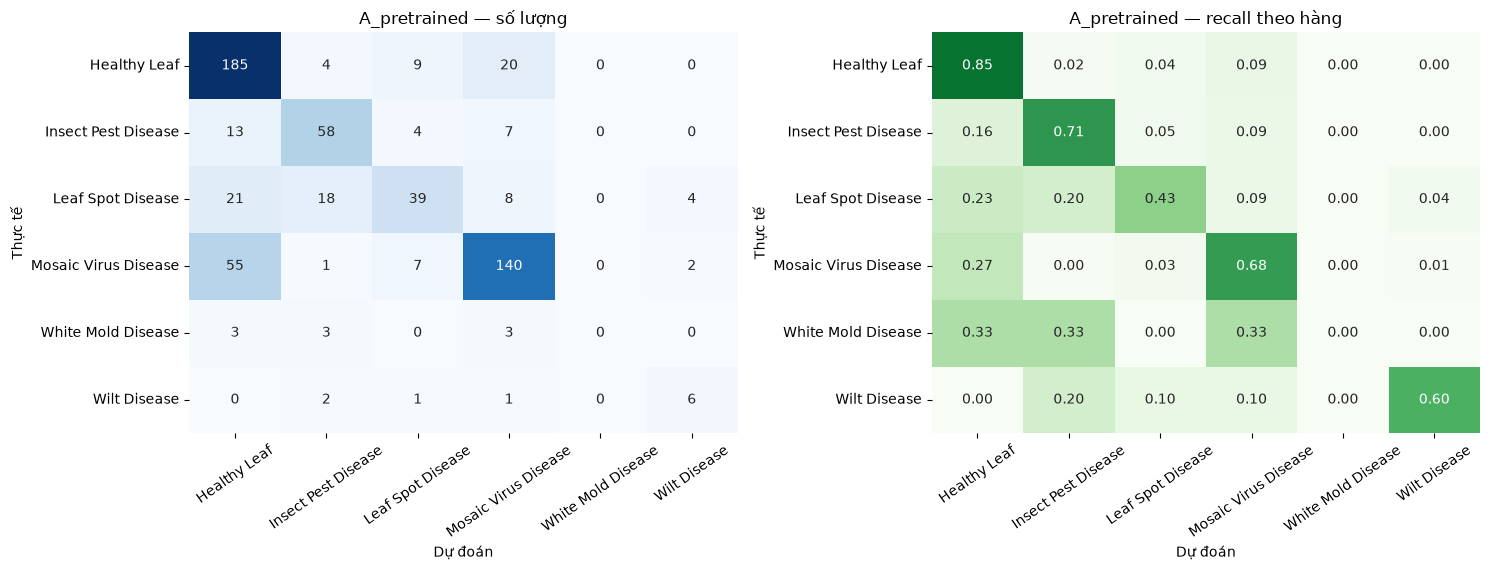

{'probs': array([[9.94473159e-01, 3.68605508e-03, 8.68701609e-04, 6.48090907e-04,
         3.20828258e-04, 3.16995829e-06],
        [9.43842292e-01, 6.29681686e-04, 4.47014160e-03, 4.92462963e-02,
         1.76598586e-03, 4.56139896e-05],
        [9.91385818e-01, 2.84464651e-04, 1.15626794e-03, 6.44914480e-03,
         7.15144095e-04, 9.14410157e-06],
        ...,
        [4.08283016e-03, 7.42198527e-03, 7.86986202e-03, 6.91805128e-03,
         5.40887145e-03, 9.68298495e-01],
        [2.72848364e-03, 7.48957135e-03, 4.44609905e-03, 2.37054750e-03,
         3.93902557e-03, 9.79026198e-01],
        [1.73496287e-02, 5.66101484e-02, 1.08375534e-01, 2.12572105e-02,
         1.72146112e-02, 7.79192865e-01]], shape=(614, 6), dtype=float32),
 'probs_tta': array([[9.8693448e-01, 6.9949683e-03, 3.4623183e-03, 1.4221132e-03,
         1.1654913e-03, 2.0647658e-05],
        [9.3474102e-01, 6.2221615e-04, 5.3339023e-03, 5.7886034e-02,
         1.3561833e-03, 6.0715716e-05],
        [9.7928941e-01, 

In [12]:
# --- Đánh giá Experiment A trên TEST ---
evaluate_result("A_pretrained", res_A)

# Experiment B — EfficientNet-B0 **train from scratch**

Cùng kiến trúc, cùng split, cùng augmentation `basic`, cùng head, cùng loss; **chỉ khác**:

* không nạp trọng số ImageNet (`pretrained=False`, khởi tạo mặc định của torchvision);
* learning rate lớn hơn (`1e-3` cho toàn mạng) vì mọi tầng đều phải học từ đầu;
* nhiều epoch hơn (`100`) và `patience` dài hơn, vì from-scratch hội tụ chậm hơn nhiều.

Kỳ vọng: thấp hơn A rõ rệt (với ~3.4k ảnh train, notebook 4 lớp trước đây đã cho thấy scratch chỉ ~0.55). Đây là đối chứng để đo giá trị của transfer learning.

Cấu hình B (khác mặc định): {'pretrained': False, 'backbone_lr': 0.001, 'warmup_epochs': 5, 'epochs': 100, 'patience': 30}
[B_scratch] nạp checkpoint đã có: B_scratch.pt (val_acc=0.7345)


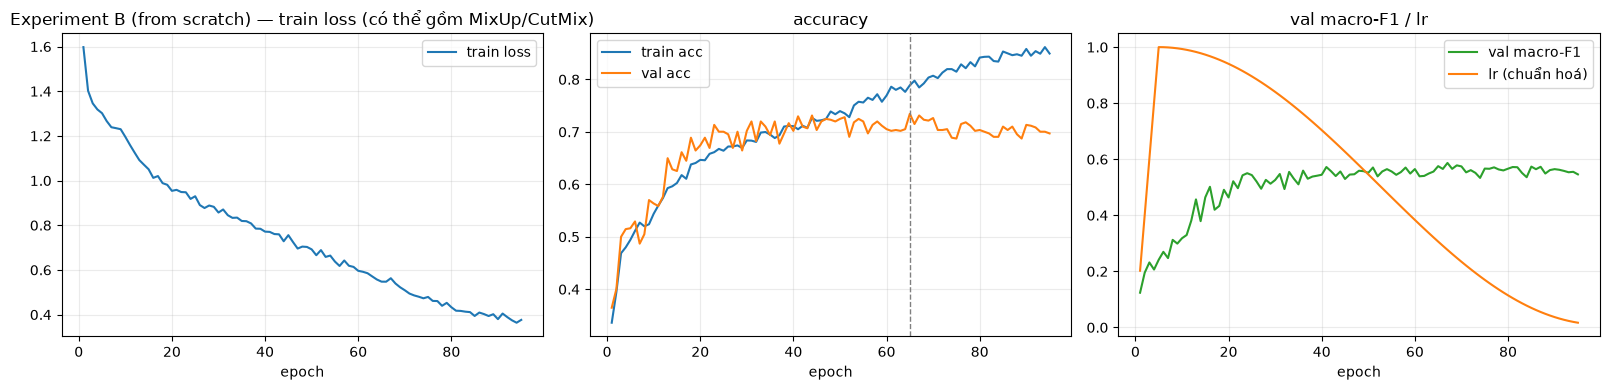

In [13]:
# ============================================================
# Experiment B — from scratch
# ============================================================
cfg_B = {**cfg_A,
         "pretrained": False,
         "backbone_lr": 1e-3, "head_lr": 1e-3, "weight_decay": 1e-4,
         "warmup_epochs": 5,
         "epochs": BUDGET["B_epochs"], "patience": 30}
print("Cấu hình B (khác mặc định):", cfg_diff(cfg_B))
res_B = train_or_load("B_scratch", cfg_B, TR, VA, verbose=1)
plot_history(res_B, "Experiment B (from scratch)", "B_history.png")


=== B_scratch — TEST ===
  1 view : acc=0.7150  (95% CI 0.678–0.751)  macro-F1=0.5526  balanced-acc=0.5354
  TTA x8: acc=0.7134  (95% CI 0.678–0.748)  macro-F1=0.5260  balanced-acc=0.5121


,precision,recall,f1-score,support
Healthy Leaf,0.7352,0.7385,0.7368,218.000
Insect Pest Disease,0.6771,0.7927,0.7303,82.000
Leaf Spot Disease,0.6562,0.4667,0.5455,90.000
Mosaic Virus Disease,0.7293,0.8146,0.7696,205.000
White Mold Disease,0.0000,0.0000,0.0000,9.000
Wilt Disease,0.8000,0.4000,0.5333,10.000
accuracy,0.7150,0.7150,0.7150,0.715
macro avg,0.5996,0.5354,0.5526,614.000
weighted avg,0.7041,0.7150,0.7047,614.000


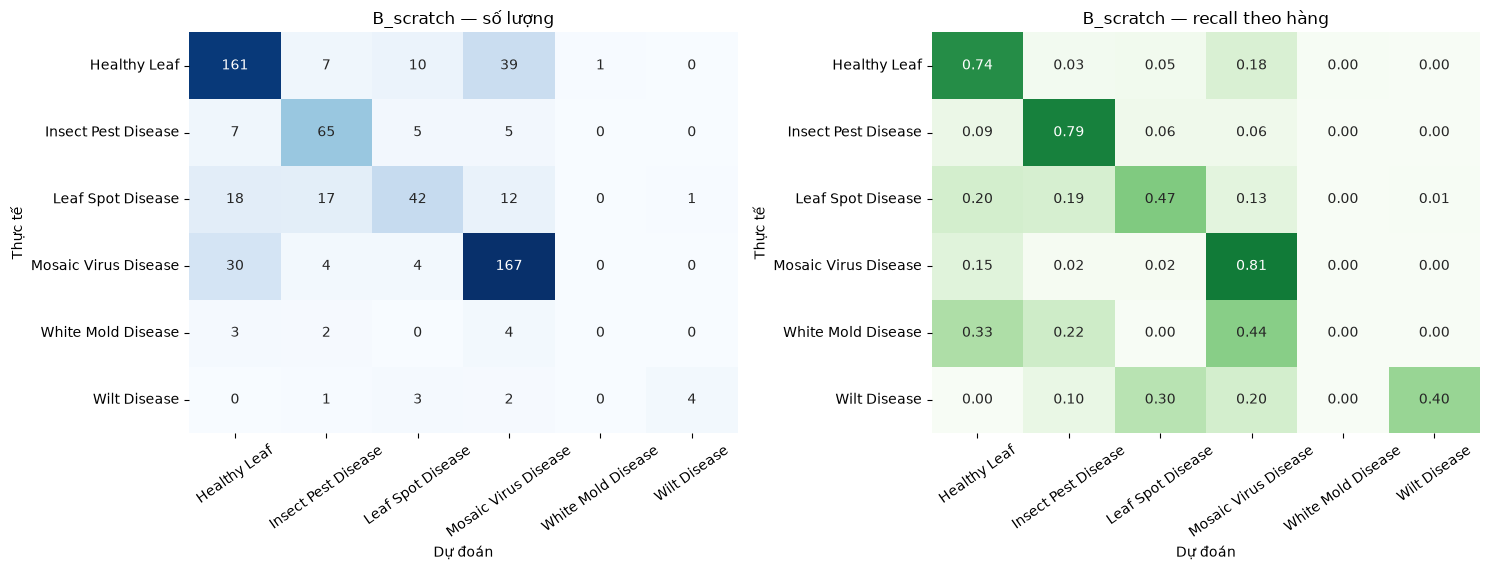

,accuracy,balanced_accuracy,macro_f1,weighted_f1,delta vs A (acc)
A pretrained,0.6971,0.5454,0.5388,0.6862,0.0000
B scratch,0.7150,0.5354,0.5526,0.7047,0.0179


In [14]:
# --- Đánh giá Experiment B trên TEST ---
evaluate_result("B_scratch", res_B)

cmp_AB = pd.DataFrame({
    "A pretrained": RESULTS["A_pretrained"]["metrics"],
    "B scratch": RESULTS["B_scratch"]["metrics"],
}).T[["accuracy", "balanced_accuracy", "macro_f1", "weighted_f1"]]
cmp_AB["delta vs A (acc)"] = cmp_AB["accuracy"] - cmp_AB.loc["A pretrained", "accuracy"]
display(cmp_AB.round(4))

# Experiment C — `RandomizedSearchCV`: loss, optimizer, imbalance, ...

Giống các notebook trước: bọc quá trình huấn luyện thành estimator của scikit-learn, dùng `PredefinedSplit` (một fold validation cố định, **không phải k-fold**) và `RandomizedSearchCV`. Mỗi trial tạo lại EfficientNet-B0 pretrained rồi fine-tune.

### Không gian tìm kiếm

| Nhóm | Tham số |
|---|---|
| **Loss (imbalance)** | `loss_type` ∈ {CE, weighted-CE, Class-Balanced CE, Focal, weighted-Focal, Class-Balanced Focal}, `focal_gamma`, `class_weight_power`, `cb_beta`, `label_smoothing` |
| **Sampler** | `sampling` ∈ {none, sqrt, balanced} |
| **Optimizer** | `optimizer` ∈ {AdamW, Adam, SGD-Nesterov, RMSprop}, `sam_rho` (có/không SAM), `weight_decay`, `backbone_lr`, `head_lr` |
| **Scheduler** | cosine+warmup hoặc ReduceLROnPlateau |
| **Fine-tune scope** | `unfreeze` ∈ {all, from3, from5}, `bn_mode` ∈ {train, freeze} |
| **Khác** | `dropout`, `hidden_dim`, `batch_size` |

Mỗi trial được **cache** (JSON) nên nếu notebook bị ngắt, chạy lại cell sẽ bỏ qua trial đã xong (miễn là giữ nguyên `random_state`).

Xếp hạng theo **validation accuracy** (macro-F1 làm tie-break). Sau khi search, **top-K** cấu hình được huấn luyện lại với lịch dài hơn để loại bớt nhiễu do validation nhỏ; cấu hình tốt nhất trên validation sẽ được đánh giá trên test.

In [15]:
# ============================================================
# C1. Estimator scikit-learn bọc train_model
# ============================================================
SEARCH_KEYS = ["backbone_lr", "head_lr", "weight_decay", "dropout", "hidden_dim", "unfreeze", "bn_mode",
               "batch_size", "optimizer", "sam_rho", "scheduler", "loss_type", "focal_gamma",
               "class_weight_power", "cb_beta", "label_smoothing", "sampling", "epochs", "patience"]
C_FIXED = dict(pretrained=True, img_size=BASE_SIZE, head_type="paper", aug="basic", warmup_epochs=2)

# Pool train + val; PredefinedSplit: -1 = train, 0 = validation
POOL = dict(idx=np.concatenate([TR["idx"], VA["idx"]]), y=np.concatenate([TR["y"], VA["y"]]))
N_POOL_TRAIN = len(TR["y"])
C_X = np.arange(len(POOL["y"])).reshape(-1, 1)
C_SPLIT = PredefinedSplit(test_fold=np.concatenate([np.full(N_POOL_TRAIN, -1), np.zeros(len(VA["y"]), dtype=int)]))
C_TRIAL_TIMES = []


class EffNetSearchEstimator(ClassifierMixin, BaseEstimator):
    def __init__(self, backbone_lr=1e-4, head_lr=1e-3, weight_decay=1e-4, dropout=0.5, hidden_dim=256,
                 unfreeze="all", bn_mode="train", batch_size=32, optimizer="adamw", sam_rho=0.0,
                 scheduler="cosine", loss_type="ce", focal_gamma=2.0, class_weight_power=0.5,
                 cb_beta=0.999, label_smoothing=0.0, sampling="none", epochs=25, patience=8):
        self.backbone_lr = backbone_lr
        self.head_lr = head_lr
        self.weight_decay = weight_decay
        self.dropout = dropout
        self.hidden_dim = hidden_dim
        self.unfreeze = unfreeze
        self.bn_mode = bn_mode
        self.batch_size = batch_size
        self.optimizer = optimizer
        self.sam_rho = sam_rho
        self.scheduler = scheduler
        self.loss_type = loss_type
        self.focal_gamma = focal_gamma
        self.class_weight_power = class_weight_power
        self.cb_beta = cb_beta
        self.label_smoothing = label_smoothing
        self.sampling = sampling
        self.epochs = epochs
        self.patience = patience

    def _cfg(self):
        return {**C_FIXED, **{k: _py(getattr(self, k)) for k in SEARCH_KEYS}}

    def fit(self, X, y):
        rows = np.asarray(X).reshape(-1).astype(int)
        if (rows >= N_POOL_TRAIN).any():
            raise RuntimeError("fit nhận chỉ số validation, hãy kiểm tra PredefinedSplit")
        cfg = self._cfg()
        key = hashlib.md5(json.dumps(cfg, sort_keys=True, default=str).encode()).hexdigest()[:16]
        cache_file = SEARCH_CACHE_DIR / f"{key}.json"
        if RESUME and cache_file.exists():
            blob = json.loads(cache_file.read_text())
            self.val_pred_ = np.asarray(blob["val_pred"], dtype=np.int64)
            self.val_metrics_ = blob["val_metrics"]
            self.best_epoch_ = blob["best_epoch"]
            print(f"  [trial cache] val_acc={blob['val_metrics']['accuracy']:.4f}")
        else:
            t0 = time.time()
            tr = dict(idx=POOL["idx"][rows], y=POOL["y"][rows])
            try:
                res = train_model(cfg, tr, VA, tag=f"C-trial", verbose=1, seed=SEED)
                probs = predict_probs(res["model"], XS[BASE_SIZE], VA["idx"], tta=1)
            except Exception:
                traceback.print_exc()
                free_memory()
                raise
            self.val_pred_ = probs.argmax(1).astype(np.int64)
            self.val_metrics_ = res["val"]
            self.best_epoch_ = int(res["best_epoch"])
            cache_file.write_text(json.dumps(dict(cfg=cfg, val_pred=self.val_pred_.tolist(),
                                                  val_metrics=res["val"], best_epoch=self.best_epoch_,
                                                  minutes=(time.time() - t0) / 60), default=str))
            C_TRIAL_TIMES.append((time.time() - t0) / 60)
            del res
            free_memory()
        self.classes_ = np.arange(NUM_CLASSES)
        return self

    def predict(self, X):
        rows = np.asarray(X).reshape(-1)
        if len(rows) != len(self.val_pred_):
            raise RuntimeError("predict chỉ hỗ trợ tập validation của PredefinedSplit")
        return self.val_pred_


print("Estimator sẵn sàng. Khoá tìm kiếm:", SEARCH_KEYS)

Estimator sẵn sàng. Khoá tìm kiếm: ['backbone_lr', 'head_lr', 'weight_decay', 'dropout', 'hidden_dim', 'unfreeze', 'bn_mode', 'batch_size', 'optimizer', 'sam_rho', 'scheduler', 'loss_type', 'focal_gamma', 'class_weight_power', 'cb_beta', 'label_smoothing', 'sampling', 'epochs', 'patience']


In [16]:
# ============================================================
# C2. Không gian tìm kiếm + chạy RandomizedSearchCV
# ============================================================
C_PARAM_DIST = {
    "backbone_lr":        loguniform(3e-5, 1e-3),
    "head_lr":            loguniform(2e-4, 5e-3),
    "weight_decay":       loguniform(1e-6, 5e-2),
    "dropout":            uniform(0.10, 0.50),                 # [0.10, 0.60]
    "hidden_dim":         [128, 256, 512],
    "unfreeze":           ["all", "from3", "from5"],
    "bn_mode":            ["train", "freeze"],
    "batch_size":         [16, 32],
    "optimizer":          ["adamw", "adam", "sgd", "rmsprop"],
    "sam_rho":            [0.0, 0.0, 0.05],                    # ~1/3 số trial dùng SAM
    "scheduler":          ["cosine", "plateau"],
    "loss_type":          ["ce", "weighted_ce", "cb_ce", "focal", "weighted_focal", "cb_focal"],
    "focal_gamma":        [0.5, 1.0, 2.0, 3.0],
    "class_weight_power": [0.25, 0.5, 0.75, 1.0],
    "cb_beta":            [0.99, 0.999, 0.9999],
    "label_smoothing":    [0.0, 0.05, 0.1],
    "sampling":           ["none", "sqrt", "balanced"],
}

C_SEARCH = RandomizedSearchCV(
    estimator=EffNetSearchEstimator(epochs=BUDGET["C_search_epochs"], patience=8),
    param_distributions=C_PARAM_DIST,
    n_iter=BUDGET["C_n_iter"],
    scoring={"accuracy": "accuracy", "macro_f1": "f1_macro"},
    refit=False,
    cv=C_SPLIT,
    random_state=47,
    n_jobs=1,                    # 1 GPU -> chạy tuần tự
    verbose=2,
    error_score=np.nan,
    return_train_score=False,
)

print(f"Bắt đầu RandomizedSearchCV: {BUDGET['C_n_iter']} cấu hình × tối đa {BUDGET['C_search_epochs']} epoch "
      f"(fold validation cố định, không phải k-fold).")
t_search = time.time()
C_SEARCH.fit(C_X, POOL["y"])
print(f"Hoàn tất search sau {(time.time() - t_search) / 60:.1f} phút.")

Bắt đầu RandomizedSearchCV: 40 cấu hình × tối đa 25 epoch (fold validation cố định, không phải k-fold).
Fitting 1 folds for each of 40 candidates, totalling 40 fits
  [trial cache] val_acc=0.7036
[CV] END backbone_lr=4.4663261756075646e-05, batch_size=32, bn_mode=train, cb_beta=0.99, class_weight_power=1.0, dropout=0.2757339029463507, focal_gamma=3.0, head_lr=0.0046620659815958245, hidden_dim=256, label_smoothing=0.05, loss_type=cb_ce, optimizer=sgd, sam_rho=0.05, sampling=sqrt, scheduler=plateau, unfreeze=all, weight_decay=7.545342096152364e-05; total time=   0.0s
  [trial cache] val_acc=0.6726
[CV] END backbone_lr=0.00010396502520821857, batch_size=32, bn_mode=freeze, cb_beta=0.99, class_weight_power=0.5, dropout=0.46671372572144165, focal_gamma=0.5, head_lr=0.00383011270360308, hidden_dim=256, label_smoothing=0.0, loss_type=focal, optimizer=adamw, sam_rho=0.0, sampling=sqrt, scheduler=plateau, unfreeze=from5, weight_decay=5.193429510505012e-05; total time=   0.0s
  [trial cache] val

,mean_test_accuracy,mean_test_macro_f1,param_backbone_lr,param_batch_size,param_bn_mode,param_cb_beta,param_class_weight_power,param_dropout,param_focal_gamma,param_head_lr,param_hidden_dim,param_label_smoothing,param_loss_type,param_optimizer,param_sam_rho,param_sampling,param_scheduler,param_unfreeze,param_weight_decay
0,0.7492,0.6927,0.0004,16,train,0.9900,0.25,0.2681,1.0,0.0010,256,0.05,ce,sgd,0.00,sqrt,plateau,from5,0.0013
1,0.7410,0.5885,0.0007,16,freeze,0.9999,1.00,0.4910,3.0,0.0027,128,0.00,focal,sgd,0.05,none,cosine,from3,0.0002
2,0.7345,0.6373,0.0002,32,train,0.9900,0.75,0.5499,3.0,0.0002,256,0.05,cb_ce,adamw,0.05,balanced,plateau,from5,0.0000
3,0.7280,0.6322,0.0006,16,freeze,0.9990,0.50,0.5020,0.5,0.0005,128,0.00,cb_focal,sgd,0.05,none,cosine,from3,0.0003
4,0.7248,0.6513,0.0002,16,train,0.9990,0.50,0.3370,1.0,0.0002,256,0.00,cb_focal,sgd,0.00,sqrt,plateau,from5,0.0000
5,0.7248,0.5623,0.0001,32,freeze,0.9900,0.50,0.5593,1.0,0.0006,256,0.05,ce,adamw,0.05,sqrt,plateau,all,0.0000
6,0.7215,0.6630,0.0000,32,train,0.9999,0.25,0.2327,0.5,0.0028,512,0.00,ce,adamw,0.00,balanced,plateau,from3,0.0208
7,0.7182,0.6379,0.0002,32,train,0.9900,1.00,0.4787,0.5,0.0002,128,0.00,weighted_focal,adamw,0.00,sqrt,cosine,from5,0.0000
8,0.6580,0.5072,0.0002,32,freeze,0.9900,0.75,0.5667,1.0,0.0010,256,0.05,focal,adam,0.00,sqrt,plateau,from5,0.0129
9,0.5896,0.4788,0.0001,16,freeze,0.9999,0.25,0.1001,1.0,0.0008,512,0.05,cb_focal,adam,0.00,sqrt,cosine,all,0.0073


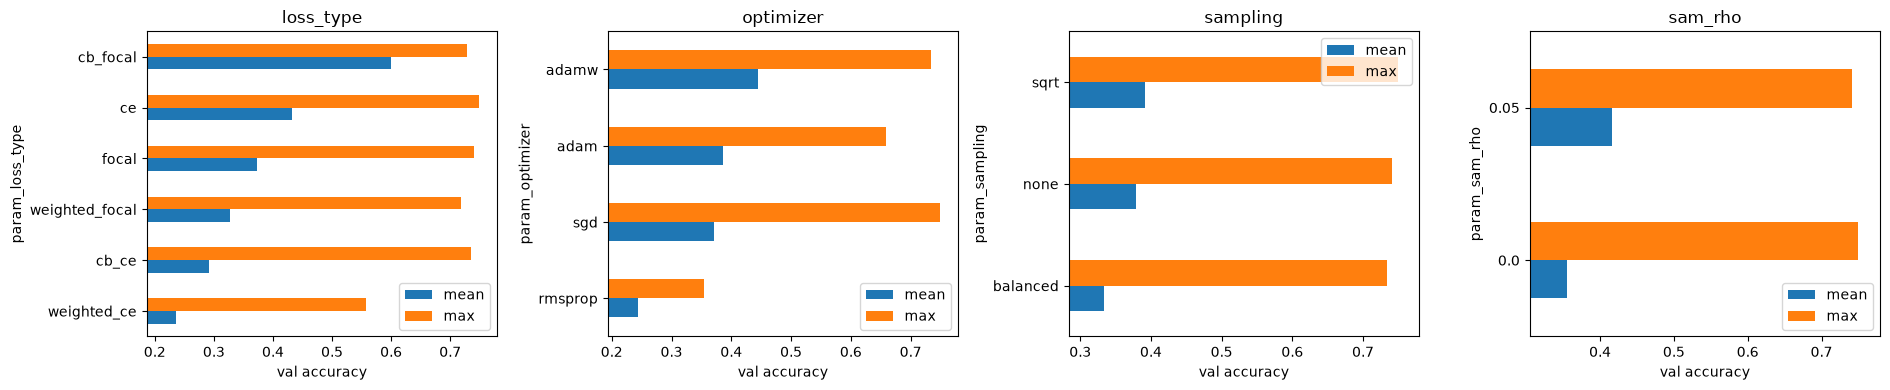

In [17]:
# ============================================================
# C3. Kết quả search, top-K cấu hình
# ============================================================
cv = pd.DataFrame(C_SEARCH.cv_results_)
if cv["mean_test_accuracy"].isna().all():
    raise RuntimeError("Tất cả trial đều lỗi, hãy xem traceback ở cell phía trên.")
cv = cv.sort_values(["mean_test_accuracy", "mean_test_macro_f1"], ascending=False).reset_index(drop=True)
param_cols = [c for c in cv.columns if c.startswith("param_")]
show_cols = ["mean_test_accuracy", "mean_test_macro_f1"] + param_cols
display(cv[show_cols].head(15).round(4))
cv.drop(columns=["params"]).to_csv(RESULTS_DIR / "C_randomized_search_results.csv", index=False)

# Phân tích: loss / optimizer / sampler nào hiệu quả (trung bình val accuracy theo nhóm)
fig, axes = plt.subplots(1, 4, figsize=(19, 4))
for ax, col in zip(axes, ["param_loss_type", "param_optimizer", "param_sampling", "param_sam_rho"]):
    g = cv.groupby(col)["mean_test_accuracy"].agg(["mean", "max", "count"]).sort_values("mean")
    g[["mean", "max"]].plot.barh(ax=ax)
    ax.set_title(col.replace("param_", ""))
    ax.set_xlim(max(0.0, g["mean"].min() - 0.05), min(1.0, g["max"].max() + 0.03))
    ax.set_xlabel("val accuracy")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "C_search_groups.png", dpi=160, bbox_inches="tight")
plt.show()


### Top-1 (val acc lúc search = 0.7492)
{'backbone_lr': 0.000386, 'batch_size': 16, 'bn_mode': 'train', 'cb_beta': 0.99, 'class_weight_power': 0.25, 'dropout': 0.268142, 'focal_gamma': 1.0, 'head_lr': 0.001038, 'hidden_dim': 256, 'label_smoothing': 0.05, 'loss_type': 'ce', 'optimizer': 'sgd', 'sam_rho': 0.0, 'sampling': 'sqrt', 'scheduler': 'plateau', 'unfreeze': 'from5', 'weight_decay': 0.001339}
  [C_final_rank1] ep 001/60 | loss 1.3681 | val_acc 0.6596 | val_f1 0.4779 | best 0.6596@1 | 7.8s
  [C_final_rank1] ep 002/60 | loss 1.0887 | val_acc 0.6971 | val_f1 0.5526 | best 0.6971@2 | 7.7s
  [C_final_rank1] ep 005/60 | loss 0.8756 | val_acc 0.7117 | val_f1 0.6475 | best 0.7117@5 | 8.0s
  [C_final_rank1] ep 010/60 | loss 0.7162 | val_acc 0.7215 | val_f1 0.6480 | best 0.7215@8 | 7.4s
  [C_final_rank1] ep 015/60 | loss 0.6186 | val_acc 0.7443 | val_f1 0.6735 | best 0.7492@14 | 7.5s
  [C_final_rank1] ep 020/60 | loss 0.5898 | val_acc 0.7345 | val_f1 0.6740 | best 0.7492@14 | 7.2s
  [C_fin

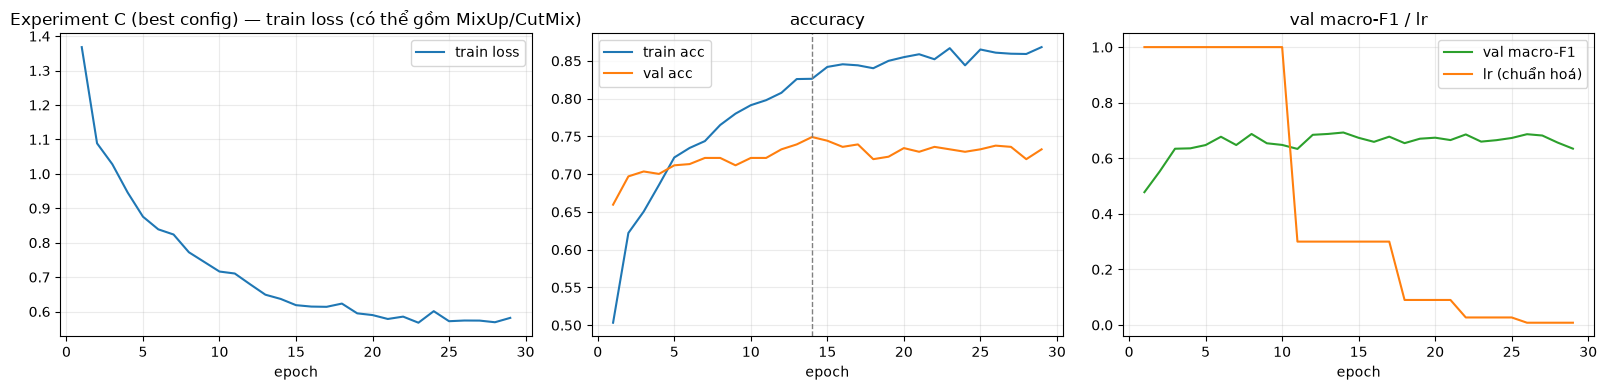

In [18]:
# ============================================================
# C4. Huấn luyện lại top-K cấu hình với lịch dài hơn -> chọn theo validation
# ============================================================
C_final_runs = []
for k in range(min(BUDGET["C_topk"], len(cv))):
    params = {kk: _py(vv) for kk, vv in cv.loc[k, "params"].items()}
    cfg_k = {**C_FIXED, **params, "epochs": BUDGET["C_final_epochs"], "patience": 15}
    print(f"\n### Top-{k + 1} (val acc lúc search = {cv.loc[k, 'mean_test_accuracy']:.4f})")
    print({kk: (round(v, 6) if isinstance(v, float) else v) for kk, v in params.items()})
    r = train_or_load(f"C_final_rank{k + 1}", cfg_k, TR, VA, verbose=1, seed=SEED + k)
    C_final_runs.append(r)
    free_memory()

best_idx = max(range(len(C_final_runs)),
               key=lambda i: (C_final_runs[i]["val"]["accuracy"], C_final_runs[i]["val"]["macro_f1"]))
res_C = C_final_runs[best_idx]
cfg_C = res_C["cfg"]
print(f"\n>>> Cấu hình C tốt nhất: top-{best_idx + 1} | val acc = {res_C['val']['accuracy']:.4f} | "
      f"val macro-F1 = {res_C['val']['macro_f1']:.4f}")
print("Khác mặc định:", cfg_diff(cfg_C))
json.dump({k: _py(v) for k, v in cfg_C.items()}, open(RESULTS_DIR / "C_best_cfg.json", "w"), indent=2)
plot_history(res_C, "Experiment C (best config)", "C_history.png")


=== C_search — TEST ===
  1 view : acc=0.7476  (95% CI 0.712–0.782)  macro-F1=0.6881  balanced-acc=0.6753
  TTA x8: acc=0.7476  (95% CI 0.712–0.780)  macro-F1=0.6380  balanced-acc=0.6104


,precision,recall,f1-score,support
Healthy Leaf,0.7642,0.8028,0.7830,218.0000
Insect Pest Disease,0.7500,0.7683,0.7590,82.0000
Leaf Spot Disease,0.6667,0.5556,0.6061,90.0000
Mosaic Virus Disease,0.7656,0.7805,0.7729,205.0000
White Mold Disease,0.5000,0.4444,0.4706,9.0000
Wilt Disease,0.7778,0.7000,0.7368,10.0000
accuracy,0.7476,0.7476,0.7476,0.7476
macro avg,0.7040,0.6753,0.6881,614.0000
weighted avg,0.7448,0.7476,0.7452,614.0000


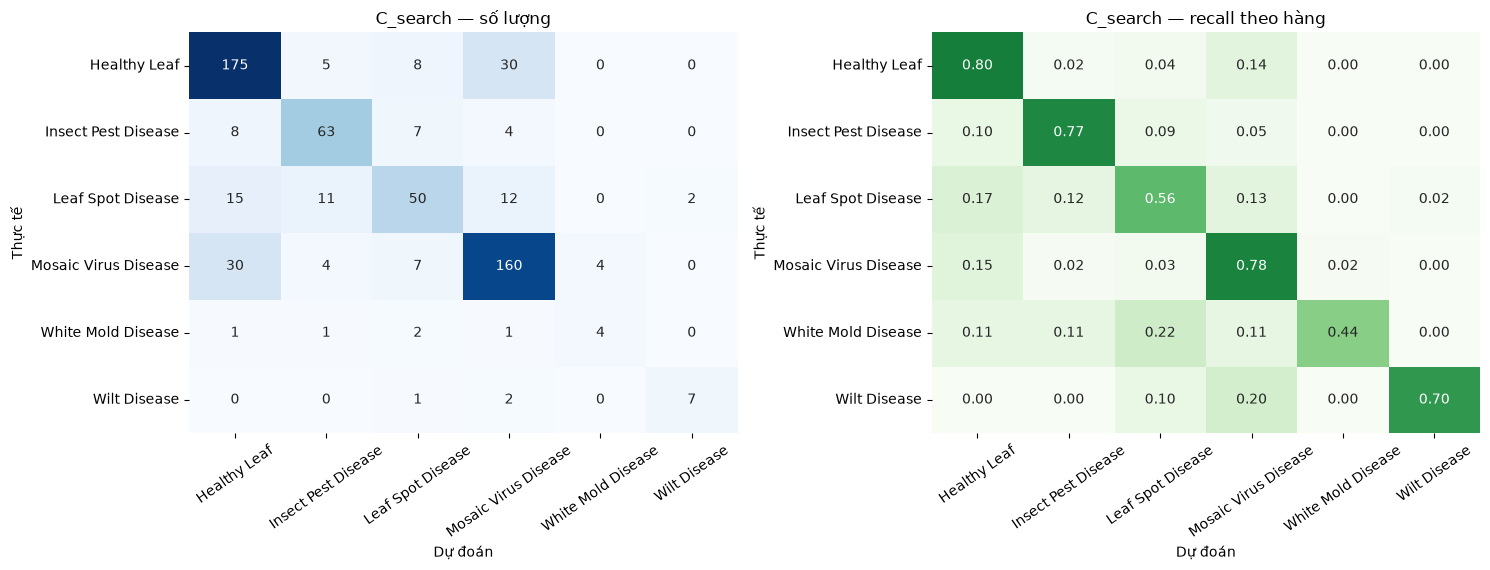

,accuracy,balanced_accuracy,macro_f1,weighted_f1
A pretrained,0.6971,0.5454,0.5388,0.6862
B scratch,0.7150,0.5354,0.5526,0.7047
C searched,0.7476,0.6753,0.6881,0.7452


In [19]:
# --- Đánh giá Experiment C trên TEST ---
evaluate_result("C_search", res_C)

cmp_ABC = pd.DataFrame({
    "A pretrained": RESULTS["A_pretrained"]["metrics"],
    "B scratch": RESULTS["B_scratch"]["metrics"],
    "C searched": RESULTS["C_search"]["metrics"],
}).T[["accuracy", "balanced_accuracy", "macro_f1", "weighted_f1"]]
display(cmp_ABC.round(4))

# Experiment D — EfficientNet-B0 **cải tiến để đạt accuracy cao nhất**

Đây là phần mình đề xuất. Ba lần thử trước (A, B, C) cho thấy hai điểm yếu của bài toán: **overfit** (train-acc cao hơn val-acc nhiều) và **hai lớp hiếm** với rất ít ảnh. Experiment D xử lý cả hai bằng các thay đổi trên chính EfficientNet-B0, bắt đầu từ **cấu hình C tốt nhất**.

### Các thành phần cải tiến (thêm tiến dần theo kiểu *greedy forward selection*)

| Bước | Thay đổi | Lý do |
|---|---|---|
| D1 | **Augmentation mạnh** (random-resized-crop, flip ngang+dọc, xoay ±30°, color jitter, blur, nhiễu, random erasing) + **MixUp/CutMix** | Giảm overfit, lá không có hướng cố định nên flip dọc/xoay hợp lý |
| D2 | **Ảnh 320×320** thay vì 224 | Vết bệnh nhỏ cần độ phân giải cao; EfficientNet được thiết kế để tăng độ phân giải |
| D3 | **Head Multi-Scale Fusion + GeM** (stage 5-8) và stochastic depth 0.3 | Dùng đặc trưng trung gian + pooling nhạy với vùng nhỏ; regularize mạnh hơn |
| D4 | Fine-tune **toàn mạng** với **layer-wise LR decay** (0.85) | Tầng sâu học nhanh hơn, tầng nông giữ đặc trưng tổng quát của ImageNet |
| D5 | **EMA** của trọng số | Trọng số mượt hơn, ổn định hơn trên validation nhỏ |
| D6 | **Lịch huấn luyện dài hơn** | Augmentation mạnh + MixUp cần nhiều epoch hơn để hội tụ |

Mỗi bước được huấn luyện thật, và **chỉ giữ lại nếu validation (accuracy, rồi macro-F1) không kém bước trước**. Test chỉ được in ra để báo cáo, không tham gia quyết định giữ/bỏ.

### Sau đó: ensemble
Cấu hình tốt nhất được huấn luyện lại bằng **5-fold stratified CV trên toàn bộ dev set (train+val)**; mỗi fold dùng phần validation của nó để chọn checkpoint. Dự đoán cuối là **trung bình xác suất của 5 mô hình + TTA 8 view** (flip/transpose). Mô hình đơn lẻ tốt nhất ở các bước D1–D6 cũng được báo cáo riêng (`D_single`) để so sánh công bằng với A/B/C.


########## D1 strong aug + MixUp/CutMix
Thay đổi so với cấu hình hiện tại: {'aug': 'strong', 'mix_prob': 0.5}
  [D1_stage] ep 001/60 | loss 1.4391 | val_acc 0.6238 | val_f1 0.4492 | best 0.6238@1 | 8.0s
  [D1_stage] ep 002/60 | loss 1.2560 | val_acc 0.6564 | val_f1 0.5609 | best 0.6564@2 | 7.8s
  [D1_stage] ep 005/60 | loss 1.1378 | val_acc 0.7101 | val_f1 0.6166 | best 0.7101@5 | 8.4s
  [D1_stage] ep 010/60 | loss 1.1008 | val_acc 0.7345 | val_f1 0.6680 | best 0.7345@10 | 16.9s
  [D1_stage] ep 015/60 | loss 1.0333 | val_acc 0.7345 | val_f1 0.6614 | best 0.7410@14 | 8.3s
  [D1_stage] ep 020/60 | loss 0.9783 | val_acc 0.7231 | val_f1 0.6296 | best 0.7410@14 | 24.1s
  [D1_stage] ep 025/60 | loss 0.9824 | val_acc 0.7329 | val_f1 0.6373 | best 0.7410@14 | 7.9s
  [D1_stage] early stopping tại epoch 29 (best epoch 14).
  [D1_stage] xong: best val_acc=0.7410 (epoch 14), 13.3 phút, params 4,337,026 (trainable 4,028,366)
  -> val acc 0.7410 / macro-F1 0.6386  (hiện tại 0.7492 / 0.6927) => BỎ



,stage,accepted,val_acc,val_f1,best_epoch,minutes,test_acc,test_acc_tta
0,D0 = cấu hình C tốt nhất,True,0.7492,0.6927,14,3.6552,0.7476,0.7476
1,D1 strong aug + MixUp/CutMix,False,0.7410,0.6386,14,13.3069,0.7378,0.7394
2,D2 + ảnh 320px,False,0.7476,0.7031,8,4.0400,0.7166,0.7215
3,"D3 + head MSF-GeM, drop_path",True,0.7508,0.7036,30,6.9215,0.7345,0.7378
4,"D4 + full FT, layer-wise LR",True,0.7573,0.7073,42,12.4032,0.7166,0.7329
5,D5 + EMA,True,0.7622,0.7082,14,7.4427,0.7231,0.7345
6,D6 + lịch dài hơn,False,0.7541,0.7007,30,14.3481,0.7231,0.7329



Cấu hình D cuối cùng (khác mặc định): {'head_type': 'msf_gem', 'hidden_dim': 512, 'dropout': 0.3, 'drop_path': 0.3, 'optimizer': 'sgd', 'backbone_lr': 0.00038574010243662323, 'head_lr': 0.0010384161106356728, 'weight_decay': 0.0013391838044598744, 'lr_decay': 0.85, 'scheduler': 'plateau', 'batch_size': 16, 'epochs': 60, 'patience': 15, 'class_weight_power': 0.25, 'focal_gamma': 1.0, 'label_smoothing': 0.05, 'cb_beta': 0.99, 'sampling': 'sqrt', 'ema_decay': 0.998}


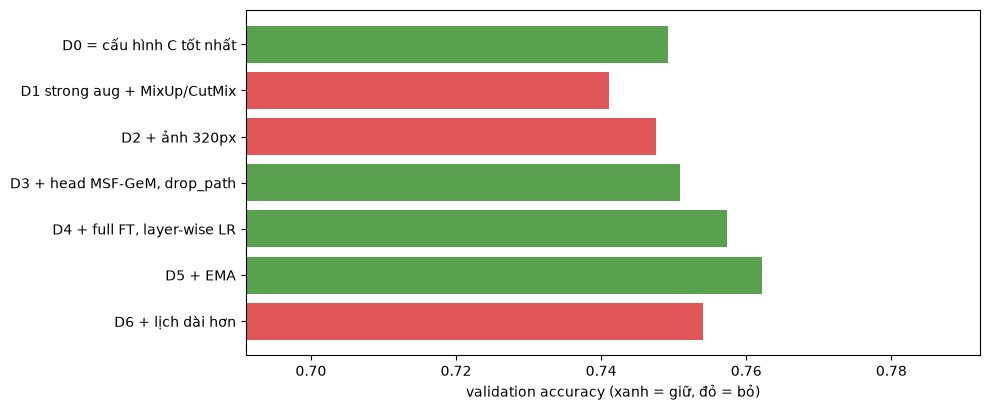

In [20]:
# ============================================================
# D1. Greedy forward selection các cải tiến
# ============================================================
D_STAGES = [
    ("D1 strong aug + MixUp/CutMix", lambda c: dict(aug="strong", mix_prob=0.5)),
    ("D2 + ảnh 320px",               lambda c: dict(img_size=HIGH_SIZE)),
    ("D3 + head MSF-GeM, drop_path", lambda c: dict(head_type="msf_gem", hidden_dim=512,
                                                    dropout=max(float(c["dropout"]), 0.3), drop_path=0.3)),
    ("D4 + full FT, layer-wise LR",  lambda c: dict(unfreeze="all", bn_mode="train", lr_decay=0.85)),
    ("D5 + EMA",                     lambda c: dict(ema_decay=0.998)),
    ("D6 + lịch dài hơn",            lambda c: dict(epochs=BUDGET["D_longer_epochs"], patience=25)),
]


def quick_test_acc(res):
    size = res["cfg"]["img_size"]
    p1 = predict_probs(res["model"], XS[size], TE["idx"], tta=1)
    pt = predict_probs(res["model"], XS[size], TE["idx"], tta=8)
    return compute_metrics(TE["y"], p1)["accuracy"], compute_metrics(TE["y"], pt)["accuracy"]


cur_cfg = dict(res_C["cfg"])
cur_val = (res_C["val"]["accuracy"], res_C["val"]["macro_f1"])
best_D_res = res_C
a1, a2 = RESULTS["C_search"]["metrics"]["accuracy"], RESULTS["C_search"]["metrics_tta"]["accuracy"]
stage_rows = [dict(stage="D0 = cấu hình C tốt nhất", accepted=True, val_acc=cur_val[0], val_f1=cur_val[1],
                   best_epoch=res_C["best_epoch"], minutes=res_C["seconds"] / 60,
                   test_acc=a1, test_acc_tta=a2)]

for si, (name, make_override) in enumerate(D_STAGES, 1):
    cand = {**cur_cfg, **make_override(cur_cfg)}
    print(f"\n########## {name}")
    print("Thay đổi so với cấu hình hiện tại:", {k: v for k, v in cand.items() if cur_cfg.get(k) != v})
    r = train_or_load(f"D{si}_stage", cand, TR, VA, verbose=1, seed=SEED + 10 + si)
    v = (r["val"]["accuracy"], r["val"]["macro_f1"])
    accepted = v >= cur_val                                    # so sánh tuple: accuracy trước, macro-F1 sau
    ta, tta_ = quick_test_acc(r)
    stage_rows.append(dict(stage=name, accepted=accepted, val_acc=v[0], val_f1=v[1],
                           best_epoch=r["best_epoch"], minutes=r["seconds"] / 60,
                           test_acc=ta, test_acc_tta=tta_))
    print(f"  -> val acc {v[0]:.4f} / macro-F1 {v[1]:.4f}  (hiện tại {cur_val[0]:.4f} / {cur_val[1]:.4f}) "
          f"=> {'GIỮ LẠI' if accepted else 'BỎ'}")
    if accepted:
        cur_cfg, cur_val = dict(r["cfg"]), v
        best_D_res = r
    else:
        del r
    free_memory()

cfg_D = cur_cfg
res_D_single = best_D_res
stage_df = pd.DataFrame(stage_rows)
display(stage_df.round(4))
stage_df.to_csv(RESULTS_DIR / "D_stage_ablation.csv", index=False)
json.dump({k: _py(v) for k, v in cfg_D.items()}, open(RESULTS_DIR / "D_best_cfg.json", "w"), indent=2)
print("\nCấu hình D cuối cùng (khác mặc định):", cfg_diff(cfg_D))

fig, ax = plt.subplots(figsize=(10, 4.2))
colors = ["#59A14F" if a else "#E15759" for a in stage_df["accepted"]]
ax.barh(stage_df["stage"][::-1], stage_df["val_acc"][::-1], color=colors[::-1])
ax.set_xlim(max(0, stage_df["val_acc"].min() - 0.05), min(1.0, stage_df["val_acc"].max() + 0.03))
ax.set_xlabel("validation accuracy (xanh = giữ, đỏ = bỏ)")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "D_stage_ablation.png", dpi=160, bbox_inches="tight")
plt.show()


=== D_single — TEST ===
  1 view : acc=0.7231  (95% CI 0.687–0.757)  macro-F1=0.5921  balanced-acc=0.5851
  TTA x8: acc=0.7345  (95% CI 0.699–0.769)  macro-F1=0.6171  balanced-acc=0.6037


,precision,recall,f1-score,support
Healthy Leaf,0.7467,0.7844,0.7651,218.0000
Insect Pest Disease,0.7262,0.7439,0.7349,82.0000
Leaf Spot Disease,0.6333,0.6333,0.6333,90.0000
Mosaic Virus Disease,0.7720,0.7268,0.7487,205.0000
White Mold Disease,0.1818,0.2222,0.2000,9.0000
Wilt Disease,0.5714,0.4000,0.4706,10.0000
accuracy,0.7231,0.7231,0.7231,0.7231
macro avg,0.6053,0.5851,0.5921,614.0000
weighted avg,0.7247,0.7231,0.7232,614.0000


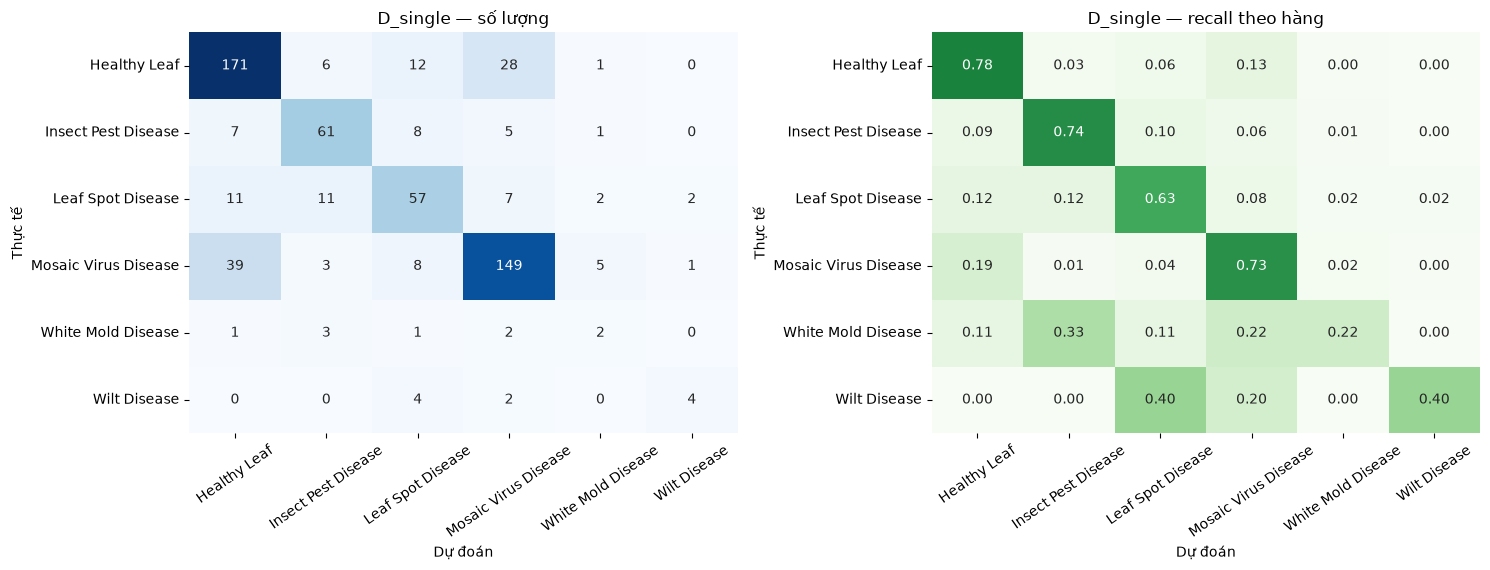

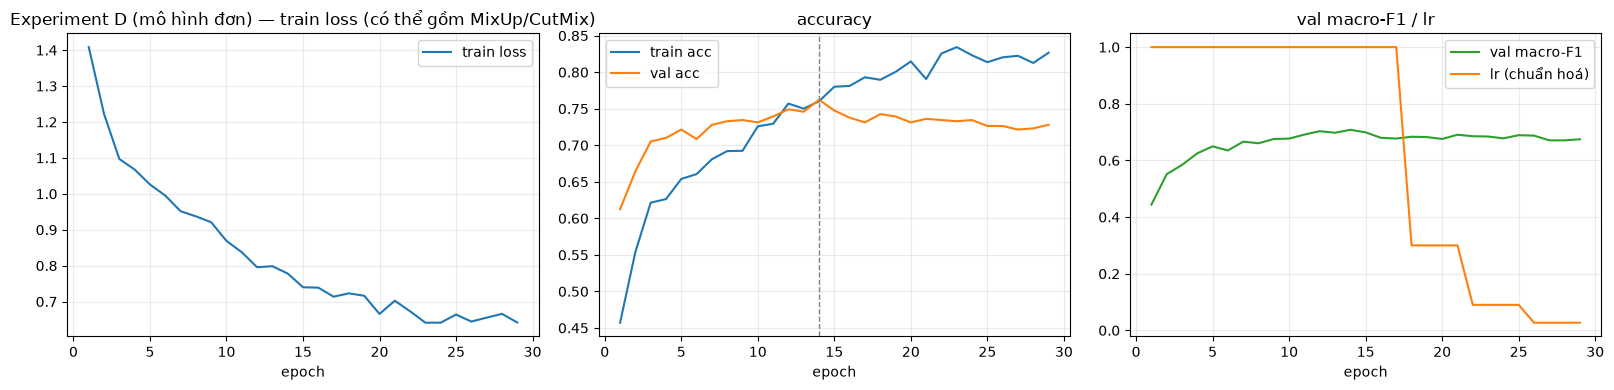

In [21]:
# --- Mô hình đơn tốt nhất của D (so sánh công bằng với A/B/C: 1 model, train split) ---
evaluate_result("D_single", res_D_single)
plot_history(res_D_single, "Experiment D (mô hình đơn)", "D_single_history.png")

## D2. Ensemble 5-fold trên toàn bộ dev set (train + val) + TTA

Mỗi fold huấn luyện một EfficientNet-B0 cải tiến với cấu hình `cfg_D` trên ~80% dev set, chọn checkpoint theo validation của chính fold đó. **Test set không bao giờ nằm trong bất kỳ fold nào.**


########## Fold 1/5 | train 2780 | val 695
  [D_fold1] ep 001/60 | loss 1.4417 | val_acc 0.6043 | val_f1 0.4451 | best 0.6043@1 | 47.2s
  [D_fold1] ep 002/60 | loss 1.2193 | val_acc 0.6115 | val_f1 0.4846 | best 0.6115@2 | 15.4s
  [D_fold1] ep 005/60 | loss 1.0290 | val_acc 0.6647 | val_f1 0.5827 | best 0.6662@4 | 16.0s
  [D_fold1] ep 010/60 | loss 0.8596 | val_acc 0.6849 | val_f1 0.6362 | best 0.6906@8 | 14.3s
  [D_fold1] ep 015/60 | loss 0.7813 | val_acc 0.6906 | val_f1 0.6450 | best 0.6935@14 | 16.5s
  [D_fold1] ep 020/60 | loss 0.7364 | val_acc 0.6849 | val_f1 0.6313 | best 0.6964@16 | 14.2s
  [D_fold1] ep 025/60 | loss 0.7079 | val_acc 0.6950 | val_f1 0.6409 | best 0.6964@16 | 14.6s
  [D_fold1] ep 030/60 | loss 0.6953 | val_acc 0.6849 | val_f1 0.6309 | best 0.6964@16 | 14.3s
  [D_fold1] early stopping tại epoch 31 (best epoch 16).
  [D_fold1] xong: best val_acc=0.6964 (epoch 16), 8.4 phút, params 4,989,798 (trainable 4,989,798)

########## Fold 2/5 | train 2780 | val 695
  [D_fol

,fold,val_acc,val_f1,best_epoch,minutes,test_acc,test_acc_tta
0,1,0.6964,0.6381,16,8.3648,0.7231,0.7296
1,2,0.7223,0.6116,41,13.8713,0.7345,0.7248
2,3,0.7295,0.6154,14,7.3428,0.7296,0.7394
3,4,0.7396,0.6684,37,12.9999,0.7068,0.7264
4,5,0.7165,0.6374,16,7.8101,0.7166,0.7394



=== D_ensemble — TEST ===
  ensemble (1 view): acc=0.7378  macro-F1=0.6332  bal-acc=0.6206
  ensemble + TTA x8: acc=0.7394  macro-F1=0.6121  bal-acc=0.6014  (95% CI 0.704–0.774)
  trung bình các fold đơn lẻ: acc=0.7221 ± 0.0109


,precision,recall,f1-score,support
Healthy Leaf,0.7317,0.8257,0.7759,218.0000
Insect Pest Disease,0.7500,0.7317,0.7407,82.0000
Leaf Spot Disease,0.6625,0.5889,0.6235,90.0000
Mosaic Virus Disease,0.8021,0.7512,0.7758,205.0000
White Mold Disease,0.1429,0.1111,0.1250,9.0000
Wilt Disease,0.6667,0.6000,0.6316,10.0000
accuracy,0.7394,0.7394,0.7394,0.7394
macro avg,0.6260,0.6014,0.6121,614.0000
weighted avg,0.7378,0.7394,0.7369,614.0000


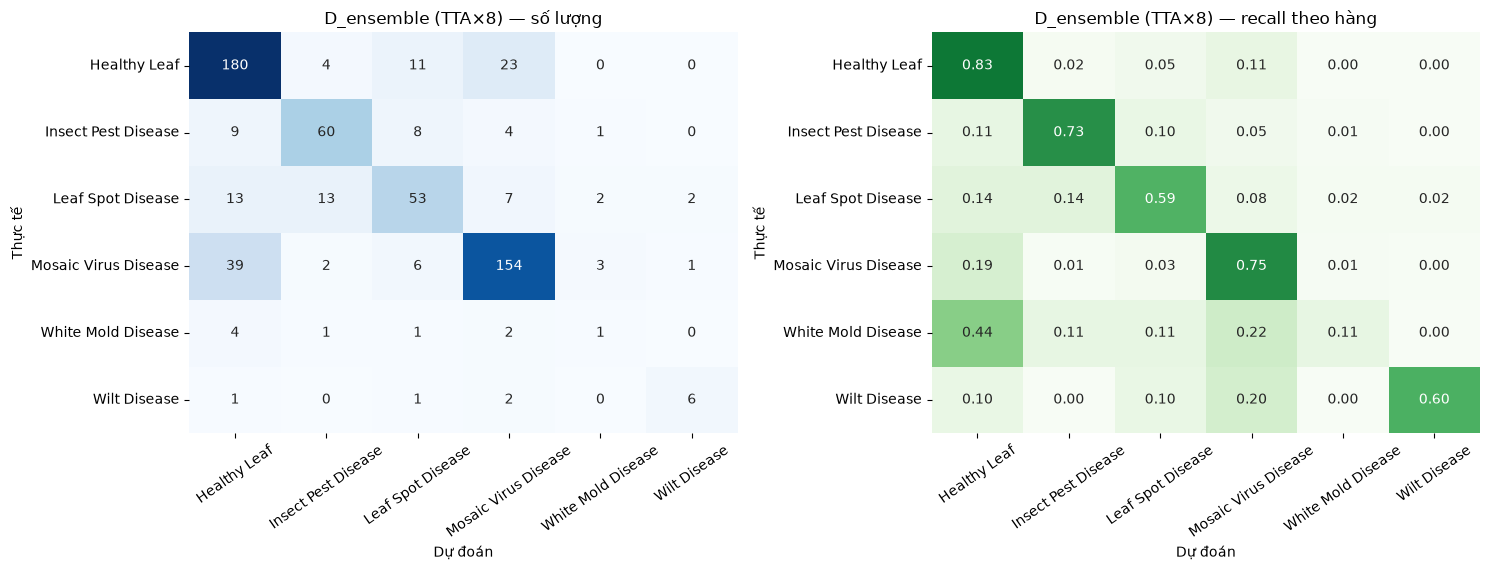

In [22]:
# ============================================================
# D2. 5-fold ensemble
# ============================================================
skf = StratifiedKFold(n_splits=BUDGET["D_folds"], shuffle=True, random_state=SEED)
size_D = cfg_D["img_size"]
fold_p1, fold_pt, fold_rows = [], [], []

for f, (a, b) in enumerate(skf.split(DEV["idx"], DEV["y"]), 1):
    tr_f = dict(idx=DEV["idx"][a], y=DEV["y"][a])
    va_f = dict(idx=DEV["idx"][b], y=DEV["y"][b])
    print(f"\n########## Fold {f}/{BUDGET['D_folds']} | train {len(a)} | val {len(b)}")
    r = train_or_load(f"D_fold{f}", cfg_D, tr_f, va_f, verbose=1, seed=SEED + 100 + f)
    p1 = predict_probs(r["model"], XS[size_D], TE["idx"], tta=1)
    pt = predict_probs(r["model"], XS[size_D], TE["idx"], tta=8)
    fold_p1.append(p1)
    fold_pt.append(pt)
    fold_rows.append(dict(fold=f, val_acc=r["val"]["accuracy"], val_f1=r["val"]["macro_f1"],
                          best_epoch=r["best_epoch"], minutes=r["seconds"] / 60,
                          test_acc=compute_metrics(TE["y"], p1)["accuracy"],
                          test_acc_tta=compute_metrics(TE["y"], pt)["accuracy"]))
    del r
    free_memory()

fold_df = pd.DataFrame(fold_rows)
display(fold_df.round(4))
fold_df.to_csv(RESULTS_DIR / "D_fold_results.csv", index=False)

register_result("D_ensemble", np.mean(fold_p1, axis=0), np.mean(fold_pt, axis=0),
                extra=dict(folds=fold_rows, cfg=cfg_D))
m, mt = RESULTS["D_ensemble"]["metrics"], RESULTS["D_ensemble"]["metrics_tta"]
print("\n=== D_ensemble — TEST ===")
print(f"  ensemble (1 view): acc={m['accuracy']:.4f}  macro-F1={m['macro_f1']:.4f}  bal-acc={m['balanced_accuracy']:.4f}")
print(f"  ensemble + TTA x8: acc={mt['accuracy']:.4f}  macro-F1={mt['macro_f1']:.4f}  bal-acc={mt['balanced_accuracy']:.4f}  "
      f"(95% CI {RESULTS['D_ensemble']['ci_tta'][0]:.3f}–{RESULTS['D_ensemble']['ci_tta'][1]:.3f})")
print(f"  trung bình các fold đơn lẻ: acc={fold_df['test_acc'].mean():.4f} ± {fold_df['test_acc'].std():.4f}")
_ = show_report("D_ensemble", use_tta=True, plot=True)

# So sánh cuối cùng A · B · C · D

Cột **1 view** là dự đoán thẳng; cột **TTA×8** trung bình 8 phép biến đổi hình học. Khoảng tin cậy 95% (bootstrap) cho thấy test set nhỏ nên không nên diễn giải chênh lệch dưới ~2%.

,Acc (1 view),95% CI,Macro-F1,Balanced acc,Acc (TTA×8),Macro-F1 (TTA)
Experiment,,,,,,
A pretrained,0.6971,0.660–0.731,0.5388,0.5454,0.7101,0.5705
B from scratch,0.7150,0.678–0.751,0.5526,0.5354,0.7134,0.5260
C RandomizedSearch,0.7476,0.712–0.782,0.6881,0.6753,0.7476,0.6380
D cải tiến (1 model),0.7231,0.687–0.757,0.5921,0.5851,0.7345,0.6171
D cải tiến (5-fold ensemble),0.7378,0.702–0.772,0.6332,0.6206,0.7394,0.6121


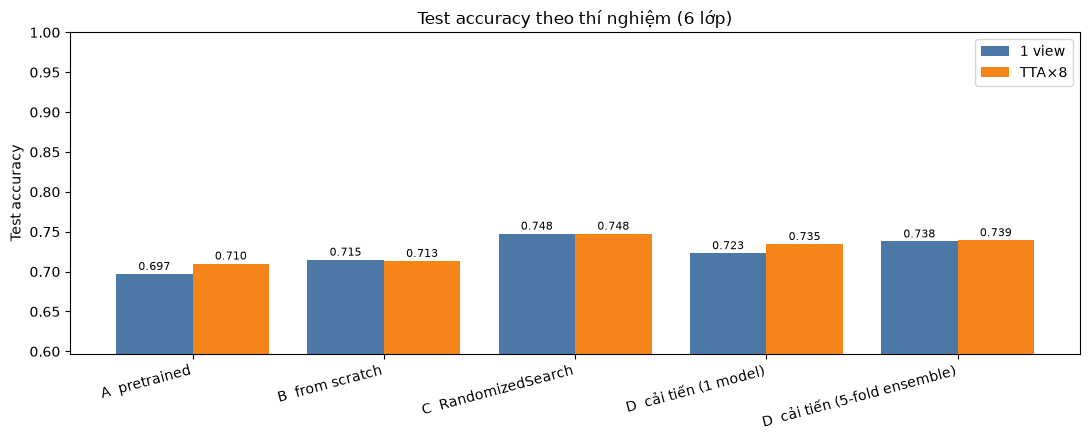

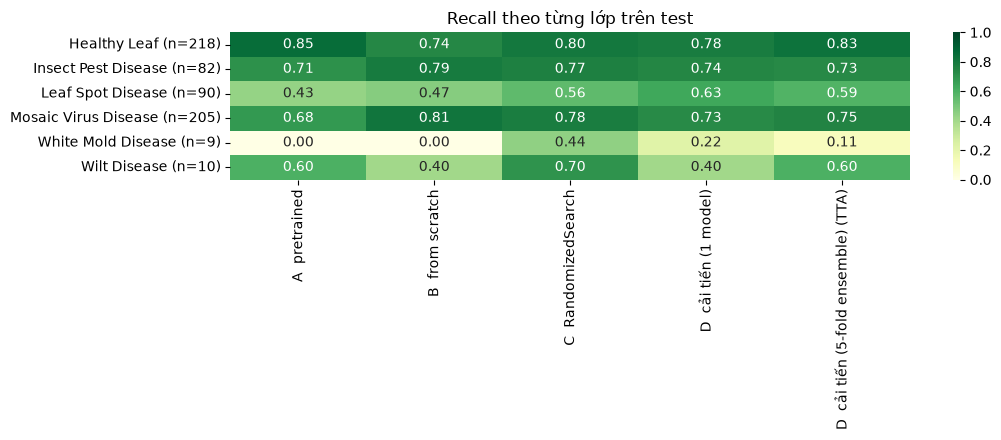

In [23]:
# ============================================================
# Bảng tổng hợp
# ============================================================
ORDER = [("A_pretrained", "A  pretrained"), ("B_scratch", "B  from scratch"), ("C_search", "C  RandomizedSearch"),
         ("D_single", "D  cải tiến (1 model)"), ("D_ensemble", "D  cải tiến (5-fold ensemble)")]
rows = []
for key, label in ORDER:
    r = RESULTS[key]
    rows.append({
        "Experiment": label,
        "Acc (1 view)": r["metrics"]["accuracy"],
        "95% CI": f"{r['ci'][0]:.3f}–{r['ci'][1]:.3f}",
        "Macro-F1": r["metrics"]["macro_f1"],
        "Balanced acc": r["metrics"]["balanced_accuracy"],
        "Acc (TTA×8)": r["metrics_tta"]["accuracy"],
        "Macro-F1 (TTA)": r["metrics_tta"]["macro_f1"],
    })
final_df = pd.DataFrame(rows).set_index("Experiment")
display(final_df.round(4))
final_df.to_csv(RESULTS_DIR / "FINAL_comparison.csv")

fig, ax = plt.subplots(figsize=(11, 4.5))
x = np.arange(len(ORDER))
ax.bar(x - 0.2, final_df["Acc (1 view)"], 0.4, label="1 view", color="#4C78A8")
ax.bar(x + 0.2, final_df["Acc (TTA×8)"], 0.4, label="TTA×8", color="#F58518")
for i, (a, b) in enumerate(zip(final_df["Acc (1 view)"], final_df["Acc (TTA×8)"])):
    ax.text(i - 0.2, a + 0.005, f"{a:.3f}", ha="center", fontsize=8)
    ax.text(i + 0.2, b + 0.005, f"{b:.3f}", ha="center", fontsize=8)
ax.set_xticks(x)
ax.set_xticklabels([l for _, l in ORDER], rotation=15, ha="right")
ax.set_ylim(max(0, final_df["Acc (1 view)"].min() - 0.1), 1.0)
ax.set_ylabel("Test accuracy")
ax.set_title("Test accuracy theo thí nghiệm (6 lớp)")
ax.legend()
plt.tight_layout()
plt.savefig(RESULTS_DIR / "FINAL_accuracy_bars.png", dpi=170, bbox_inches="tight")
plt.show()

# Recall theo từng lớp
rec = {}
for key, label in ORDER:
    pred = (RESULTS[key]["probs_tta"] if key == "D_ensemble" else RESULTS[key]["probs"]).argmax(1)
    cm = confusion_matrix(TE["y"], pred, labels=np.arange(NUM_CLASSES))
    rec[label + (" (TTA)" if key == "D_ensemble" else "")] = cm.diagonal() / np.maximum(cm.sum(1), 1)
rec_df = pd.DataFrame(rec, index=[f"{c} (n={n})" for c, n in zip(CLASSES, np.bincount(TE["y"], minlength=NUM_CLASSES))])
plt.figure(figsize=(11, 4.5))
sns.heatmap(rec_df, annot=True, fmt=".2f", cmap="YlGn", vmin=0, vmax=1)
plt.title("Recall theo từng lớp trên test")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "FINAL_per_class_recall.png", dpi=170, bbox_inches="tight")
plt.show()